# `nmrtools` - Jupyter Usage Examples

This tutorial notebook walks users through the installation and basic methods implemented in `nmrtools`

## 0. Installation

First, we need to install the package. Download the wheel file (.whl) and place anywhere on your computer. Then run the cell below.

In [7]:
# In line below, replace with your path to the wheel file
#%pip uninstall -y "C:\Users\quark\OneDrive\Documents\openNMR\dist\opennmr-0.1.0-py3-none-any.whl"
# In line below, replace with your path to the wheel file
%pip install "C:\Users\quark\OneDrive\Documents\openNMR\dist\opennmr-0.1.0-py3-none-any.whl"

Processing C:\Users\quark\OneDrive\Documents\openNMR\dist\opennmr-0.1.0-py3-none-any.whl
Note: you may need to restart the kernel to use updated packages.


### Module imports

In [1]:
# Magic line (Beginning with %) may need the following: !pip install ipympl ipywidgets
# The magic line just allows for an interactive interface for users to zoom-in over data
%matplotlib widget 
import sys
import numpy as np
import matplotlib.pyplot as plt
import opennmr.notebook as nmr
from opennmr.notebook.plotting import setup_plotting
setup_plots = setup_plotting()

Every example below assumes `nmr` has been imported this way (cell above). Replace
the `datapath` strings with your own Bruker experiment directories (the
folder containing `acqus` and `pdata/`).

## 1. Import and plot a 1-d spectrum, with optional VOCS processing



### 1.1. Manual import & plot yourself

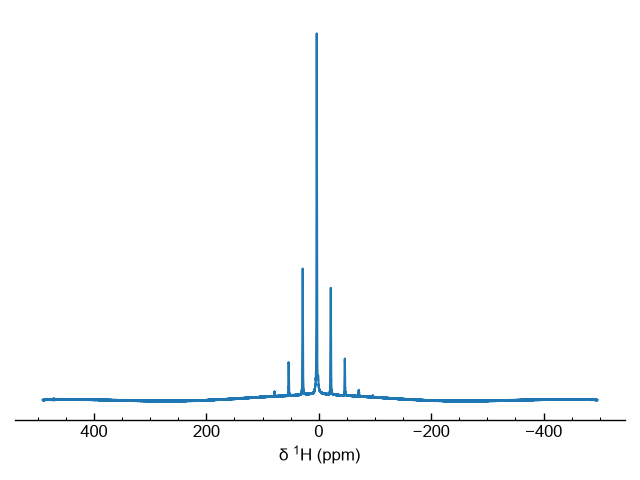

In [3]:
spec = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1")

fig, ax = plt.subplots()
ax.plot(spec["x_ppm"], spec["normalised_real_spectrum"])

ax.invert_xaxis() # <--- to get the axis the "right" way around
ax.tick_params('x', direction = 'in', labelsize = 'large')
ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.set_xlabel(nmr.NUC_label(spec["nuclide"]), fontsize = 'large')

plt.tight_layout()
plt.show()

### 1.2. Using the built-in plotting function

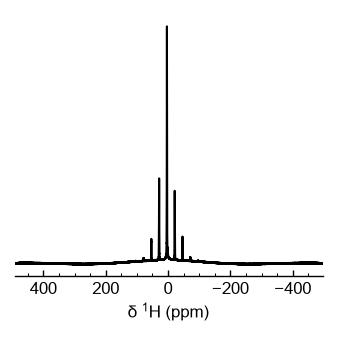

In [5]:
fig, ax = nmr.NMR1dplot(
    r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1",
    procno=[1],
    normalize=True,
    color='black',
)

Overlaying several spectra (e.g. a stack of samples) just means passing
a list of paths — they get an automatic colour gradient:

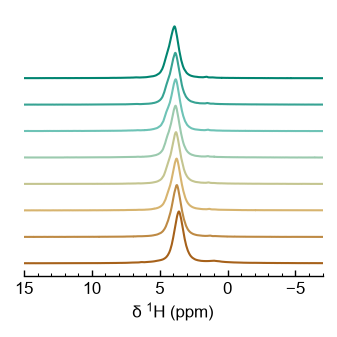

In [6]:
fnames = [r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\4",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\7",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\10",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\13",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\16",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\19",
          r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\22"]

fig, ax = nmr.NMR1dplot(
    fnames,
    #procno=[1, 1, 1],
    color='diverging',   # or a named matplotlib colormap, e.g. 'coolwarm'
    yoffset=-0.5,
    xlims= [-7,15]
)

### 1.3. Adding VOCS Processing

VOCS (Variable Offset Cumulative Spectroscopy) combines several
sub-spectra acquired at different carrier offsets, each corrected for
its own finite-pulse excitation profile, into one broadband spectrum.
`NMR1dplot` does this for you when `vocs_sum=True` — just pass the list
of VOCS sub-spectra as `data_paths`:

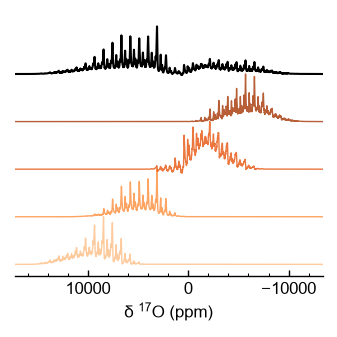

In [4]:
vocs_paths = [r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999912",
              r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999913",
              r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999914",
              r"C:\Users\quark\OneDrive\Documents\NMR\500MHz\15_02_26_Li2MnO3_O17_1_3mm\999915",]

fig, ax = nmr.NMR1dplot(
    vocs_paths,
    #procno=[1, 1, 1],
    vocs_sum=True,
    plot_vocs_parts=True,     # also show each individual VOCS piece
    vocs_pulse="P1",          # acqus parameter holding the excitation pulse length
    vocs_npoints=8192,        # points in the common interpolation axis
    vocs_average=False,       # sum (not average) the pieces
    vocs_yoffset=1.0,
    vocs_colors=['#fdbe85','#fd8d3c','#e6550d','#a63603'],
)

If you want the *processed data itself* (*e.g.*, to fit or inspect it)
rather than just a plot, call the underlying function directly:

In [15]:
vocs_result = nmr.VOCSSum(vocs_paths, pulse="P1", npoints=8192)

vocs_result["ppm"]                  # common ppm axis
vocs_result["VOCS_sum"]             # summed spectrum
vocs_result["interpolated_slices"]  # each piece, interpolated onto the common axis
vocs_result["slices"]               # each piece's raw NMR1dimport() output

[{'x_ppm': array([17277.99215987, 17277.87963055, 17277.76710122, ...,
          2528.886084  ,  2528.77355467,  2528.66102535], shape=(131072,)),
  'x_Hz': array([1171442.4201535 , 1171434.79070076, 1171427.16124802, ...,
          171457.67905898,  171450.04960624,  171442.4201535 ],
        shape=(131072,)),
  'real_spectrum': array([0., 0., 0., ..., 0., 0., 0.], shape=(131072,)),
  'normalised_real_spectrum': array([0.06586693, 0.06589351, 0.06592227, ..., 0.06580193, 0.06582099,
         0.06584271], shape=(131072,)),
  'imag_spectrum': array([-0., -0., -0., ..., -0., -0., -0.], shape=(131072,)),
  'normalised_imag_spectrum': array([0.74077492, 0.74085685, 0.74093682, ..., 0.74051764, 0.74060526,
         0.74069104], shape=(131072,)),
  'nuclide': '17O',
  'BF1': 67.799908,
  'SFO1': 67.7996846690465,
  'path': 'C:\\Users\\quark\\OneDrive\\Documents\\NMR\\500MHz\\15_02_26_Li2MnO3_O17_1_3mm\\999912'},
 {'x_ppm': array([13277.97898394, 13277.86645462, 13277.75392529, ...,
         

Or, to VOCS-correct a single already-imported spectrum in place (no
combination with other spectra):

In [17]:
spec = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\1")
spec = nmr.apply_VOCS(spec, pulse="P1")

### 1.4 Adding and subtracting 1-d spectra

`nmrtools.arithmetic` combines any number of 1-d spectra with signed
weights, even when they don't share an identical ppm axis (different
`SW`/`SI`, slightly different referencing) -- every input spectrum is
interpolated onto one common axis first (ppm by default, since ppm is
field-independent; pass `x_unit="Hz"` if all inputs share the same `SFO1`).

- `combine_spectra` returns just the common axis, the combined trace,
  and the (unscaled) interpolated inputs -- handy for a quick plot.
- `combine_spectra_as_results` wraps the same computation in a dict
  shaped like an `NMR1dimport` result, so the combined spectrum can be
  fed straight into `fit_spectrum`, `NMR1dplot_with_fit`, etc.


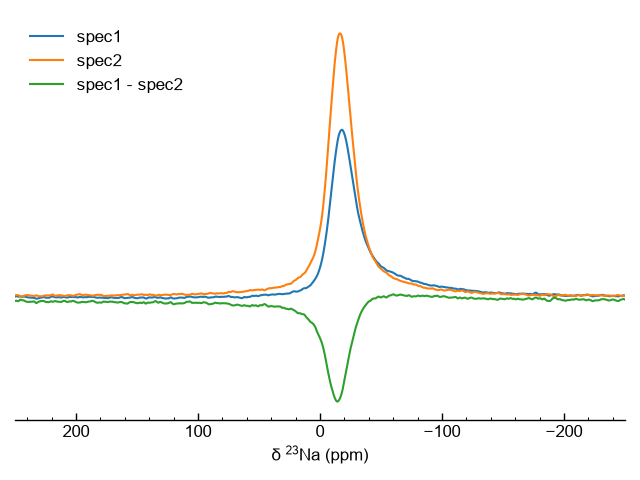

In [18]:
fname1 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\231"
fname2 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\232"

spec1 = nmr.NMR1dimport(fname1)
spec2 = nmr.NMR1dimport(fname2)

# spec1 - spec2, interpolated onto their common (overlapping) ppm range
diff = nmr.combine_spectra_as_results([spec1, spec2], ops=['+', '-'])

##########

fig, ax = plt.subplots()

ax.plot(spec1["x_ppm"], spec1["real_spectrum"], label='spec1')
ax.plot(spec2["x_ppm"], spec2["real_spectrum"], label='spec2')

ax.plot(diff["x_ppm"], diff["real_spectrum"], label='spec1 - spec2')

ax.set_xlim([-250, 250])
ax.invert_xaxis() # <--- to get the axis the "right" way around
ax.tick_params('x', direction = 'in', labelsize = 'large')
ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.set_xlabel(nmr.NUC_label(spec1["nuclide"]), fontsize = 'large')

ax.legend(frameon=False, loc=2)

plt.tight_layout()
plt.show()


For a *difference* spectrum, leave `common_range` at its default,
`'intersection'` -- only the region covered by *every* input spectrum is
used. Using `'union'` instead would zero-fill each spectrum outside its
own original range, which would manufacture a spurious "signal" in
exactly the region a difference spectrum is meant to reveal, not create.
`'union'` (zero-filled) is the convention `VOCSSum` uses instead, which
is the right choice when *summing* VOCS components.

`scaling_factors` weight each spectrum before combining -- e.g. to
correct for a mass/scan-count mismatch that wasn't already handled at
import time (`NMR1dimport(..., mass=...)`), or simply to compute
something like `2*spec1 - spec2`:


In [19]:
fname1 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\231"
fname2 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\232"

spec1 = nmr.NMR1dimport(fname1)
spec2 = nmr.NMR1dimport(fname2)

weighted_diff = nmr.combine_spectra_as_results(
    [spec1, spec2], ops=['+', '-'], scaling_factors=[2.0, 1.0],
)


The lower-level `combine_spectra` takes any number of spectra at once
and hands back the raw arrays (rather than an `NMR1dimport`-shaped
dict) -- useful for a quick look, or when you don't need the result to
feed into the fitting functions. `npoints` and `interp_kind` control the
resolution and interpolation order of the common axis:


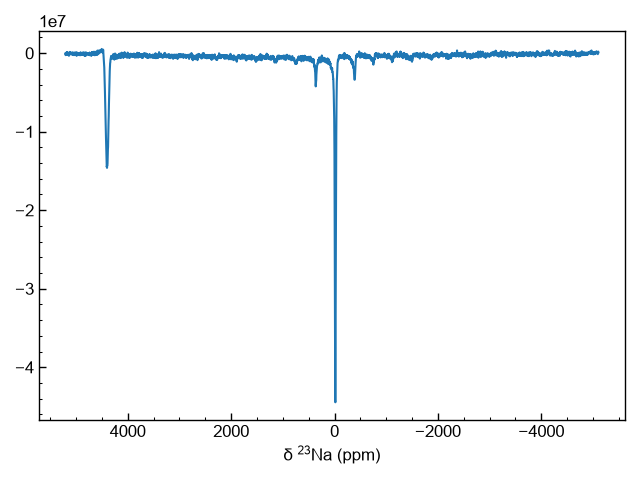

In [20]:
fname3 = r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_1H_13C_23Na_Na2CoFeCN6_D2O_Neutron_20251206\232"
spec3 = nmr.NMR1dimport(fname3)

combo = nmr.combine_spectra(
    [spec1, spec2, spec3], ops=['+', '-', '-'],
    scaling_factors=[1.0, 1.0, 0.5],
    common_range='intersection', npoints=4096, interp_kind='linear',
)

fig, ax = plt.subplots()
ax.plot(combo["x_ppm"], combo["combined_spectrum"])
ax.invert_xaxis()
ax.set_xlabel(nmr.NUC_label(spec1["nuclide"]))
plt.tight_layout()
plt.show()


### 1.5 Plotting several 1-d spectra as a heatmap

For a series of spectra that vary along some third axis -- a VT (variable-temperature) series, a titration, a kinetic run -- it's often clearer to look at them as rows of a 2-d heatmap than as an offset stack. `NMR1dheatmap` takes the same kind of `data_paths` list as `NMR1dplot`, interpolates every spectrum onto one common ppm/Hz axis (the same interpolation `combine_spectra` uses), and displays the stack as an image instead:


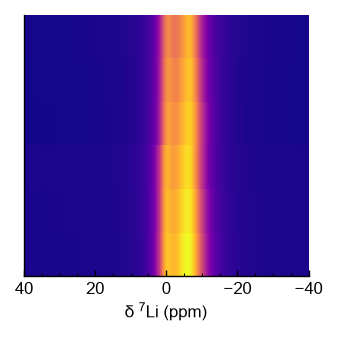

In [21]:
fnames_VT = [r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\4",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\8",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\12",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\16",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\20",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\24"]

fig, ax, im = nmr.NMR1dheatmap(
    fnames_VT,
    normalize=False,
    cmap='plasma',
    xlims=[-40, 40],
)


By default the y-axis has no ticks at all -- the rows are just "spectrum 1, 2, 3, ..." in the order given. If you have a real value per spectrum (here, the VT series' set temperatures), pass it as `y_values` and turn ticks on with `y_ticks='all'` (one tick per row) or `y_ticks='auto'` (an automatically-thinned number of ticks, useful once you have many spectra). A colourbar and its label are opt-in via `colorbar`/`colorbar_label`:


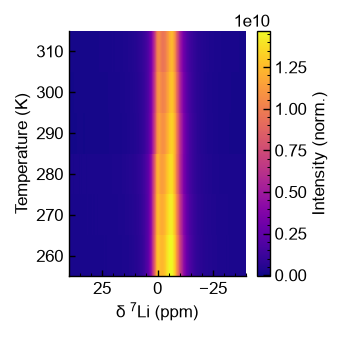

In [22]:
temperatures = [260,270,280,290,300,310]  # degC, one per entry in fnames

fnames_VT = [r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\4",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\8",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\12",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\16",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\20",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\24"]


fig, ax, im = nmr.NMR1dheatmap(
    fnames_VT,
    normalize=False,
    y_values=temperatures,
    y_ticks='all',           # or 'auto' for a thinned-out set of ticks
    ylabel='Temperature (K)',
    xlims=[-40, 40],
    cmap='plasma',
    colorbar=True,
    colorbar_label='Intensity (norm.)',
)


`NMR1dheatmap` is also wired directly into `NMR1dplot` -- pass `heatmap=True` and the same `y_values`/`y_ticks`/`ylabel` keywords (prefixed `heatmap_cmap`, `heatmap_vmin`/`heatmap_vmax`, `heatmap_colorbar`, `heatmap_colorbar_label` for the heatmap-only options that would otherwise clash with `NMR1dplot`'s own `color` argument), if you'd rather not import a second function:


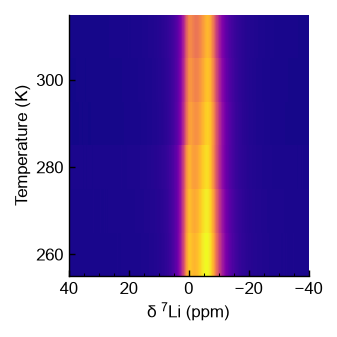

In [23]:
temperatures = [260,270,280,290,300,310]  # degC, one per entry in fnames

fnames_VT = [r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\4",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\8",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\12",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\16",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\20",
             r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p5V_20251126\24"]

fig, ax, im = nmr.NMR1dplot(
    fnames_VT,
    heatmap=True,
    normalize=False,
    y_values=temperatures,
    y_ticks='auto',
    y_tick_number=4,
    ylabel='Temperature (K)',
    heatmap_cmap='plasma',
    xlims=[-40,40],
)


## 2. Import and plot a 2-d dataset, extract a row and a column, and plot everything together (all at once)

### 2.1. Import once, plot manually

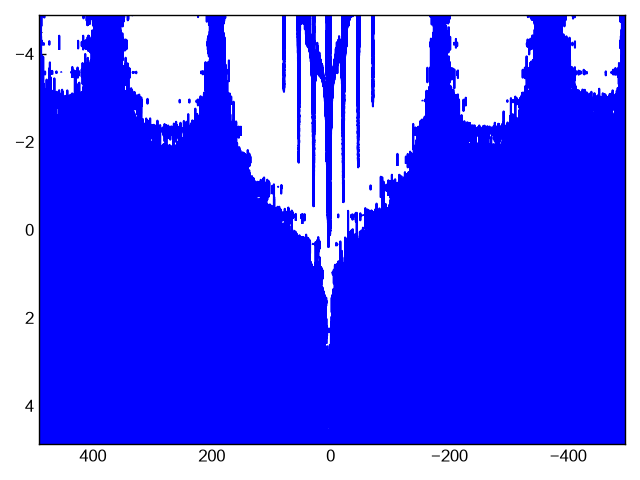

In [24]:
ds = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_1H_2H_113Cd_Na2CdFeCN6_D2O_VT_150126A_20260727\2", 
                     procno=1, homonuclear=False)

# ds["spectrum"] is the 2D matrix, shape (n_F1, n_F2)
fig, ax = plt.subplots()
ax.contour(ds["x_ppm"], ds["y_ppm"], ds["spectrum"], levels=100, colors='blue')
ax.invert_xaxis()
ax.invert_yaxis()

plt.tight_layout()
plt.show()

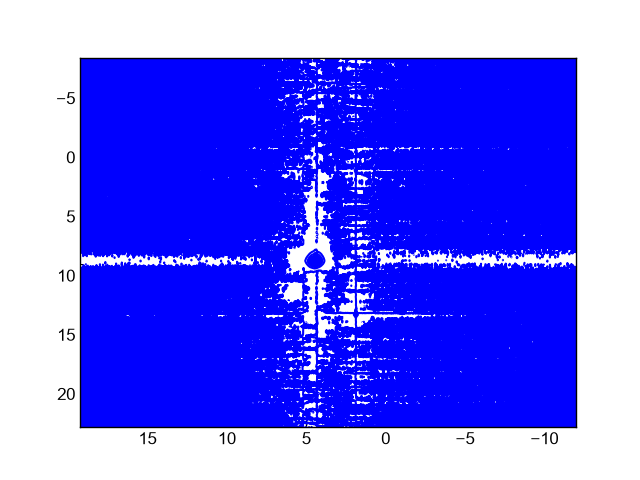

In [25]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

fig, ax = plt.subplots()
ax.contour(DQSQ["x_ppm"], DQSQ["y_ppm"], DQSQ["spectrum"], levels=15, colors='blue')
ax.invert_xaxis()
ax.invert_yaxis()

### 2.2. Contour plot with the built-in plotter

For a homonuclear double-quantum (or other multiple-quantum) correlation
spectrum, overlay the relevant diagonal(s):

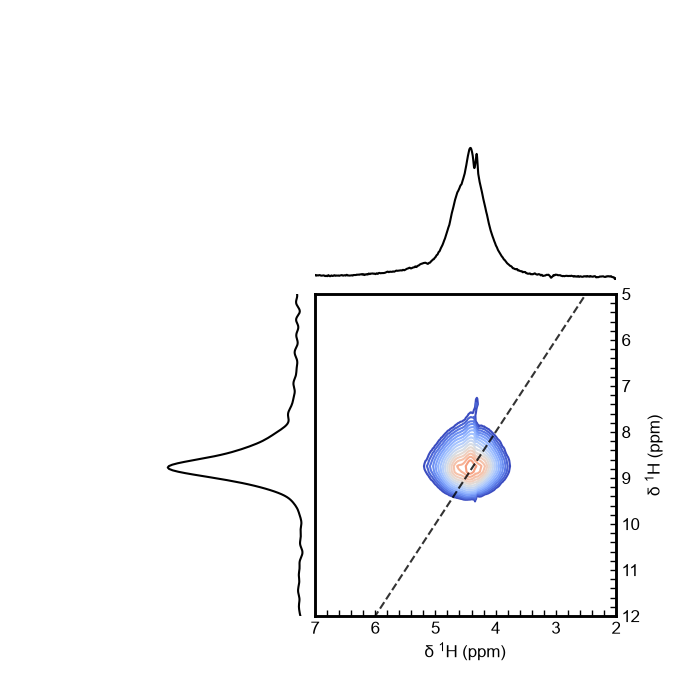

In [26]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

fig, ax = nmr.NMR2Dplotter(
    DQSQ,                          # or pass the path directly instead of DQSQ
    homonuclear=True,
    colour_spectra='coolwarm',     # None = black contours; or e.g. 'coolwarm'
    show_nQ_line=True,
    clevels=20,
    factor=5e-2,                   # lowest contour level, as a fraction of the max
    nQ=[2],                        # single- and double-quantum diagonals
    nQ_colors=['black'],
    xlims=[7, 2], ylims=[12, 5],
    proj_scale=1.5,
    show_projections=True         # or 'f1' or 'f2' to only have projections for one axis
)

### 2.3. Extract a row and a column

Rows fix an F1 position and span F2; columns fix an F2 position and span
F1 (matches TopSpin’s own row/column trace convention — see the
`nmrtools.two_d` module docstring - access *via* `nmr.two_d?` if you want the full explanation).

In [27]:
row = nmr.NMR2d_get_trace(DQSQ, axis="f1", shift=8.7)   # nearest F1 position to 8.7 ppm
col = nmr.NMR2d_get_trace(DQSQ, axis="f2", shift=4.4)   # nearest F2 position to 4.4 ppm

# or by 1-based index instead of shift:
row = nmr.NMR2d_get_trace(DQSQ, axis="f1", index=464)

print(row["x"], row["y"])                       # the extracted trace
print("Row shift = ", row["shift"])             # the actual position it was extracted at
print("Row width = ", row["width"])             # how many adjacent points were combined (default 1)

[ 19.25230555  19.24849111  19.24467667 ... -11.98416054 -11.98797499
 -11.99178943] [-242365 -224529 -202067 ... -230673 -241188 -247842]
Row shift =  8.680590332241465
Row width =  1


To pull several rows/columns at once (*e.g.*, every 10th row across a
range), use the batch version, which is what you’ll normally want before
fitting:

In [28]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

slices = nmr.NMR2D_get_slices(
    DQSQ,
    #rows=[440, 450, 460],       # by index
    row_shifts=[9.0, 8.8, 8.6],     # and/or by shift -- combined, de-duplicated
    row_width=1,                 # sum this many adjacent rows for extra S/N
    columns=[3870, 3910],
    column_width=1,
)

#slices["rows"]      # list of trace dicts, sorted by position
#slices["columns"]

for i in range(0,int(len(slices['columns']))):
    print(slices['columns'][i].keys())
    print(slices['columns'][i]['shift'])

dict_keys(['x', 'x_Hz', 'x_is_ppm', 'y', 'axis', 'slice_type', 'index', 'shift', 'shift_unit', 'width', 'nuclide', 'SFO1', 'pseudo_2d', 'datapath'])
4.494229191868478
dict_keys(['x', 'x_Hz', 'x_is_ppm', 'y', 'axis', 'slice_type', 'index', 'shift', 'shift_unit', 'width', 'nuclide', 'SFO1', 'pseudo_2d', 'datapath'])
4.34165150913636


### 2.4. Plot the extracted row/column, alongside the contour plot

c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\two_d.py:1914: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots()


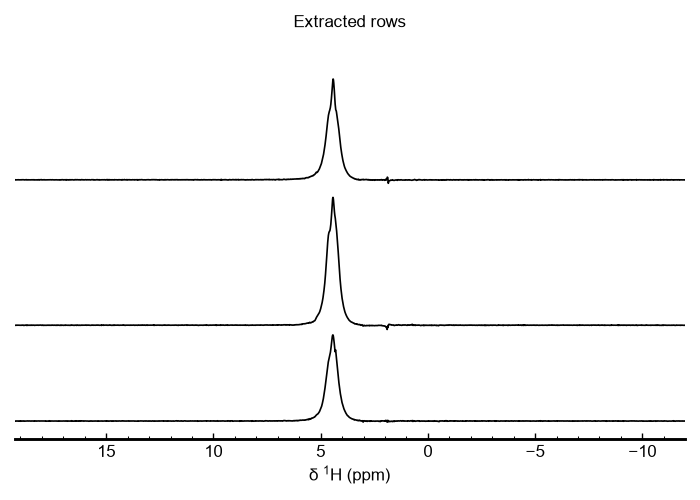

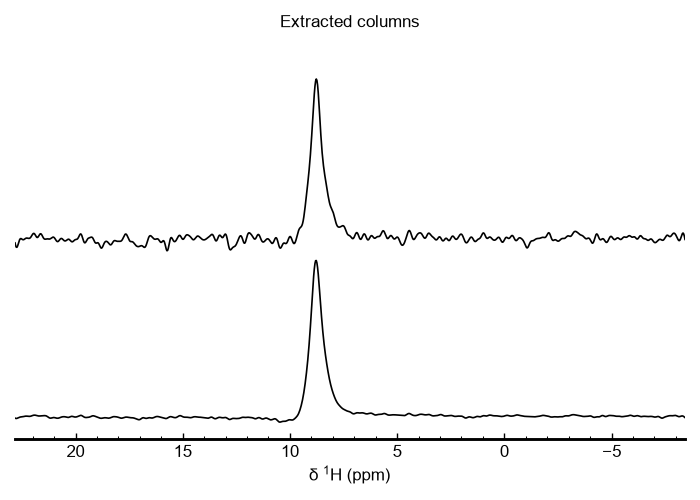

In [29]:
fig, ax = nmr.NMR2D_plot_slices(slices, mode="rows")
fig, ax = nmr.NMR2D_plot_slices(slices, mode="columns")

To show the contour plot and the extracted slices side by side (or
stacked, or in a grid) in one figure:

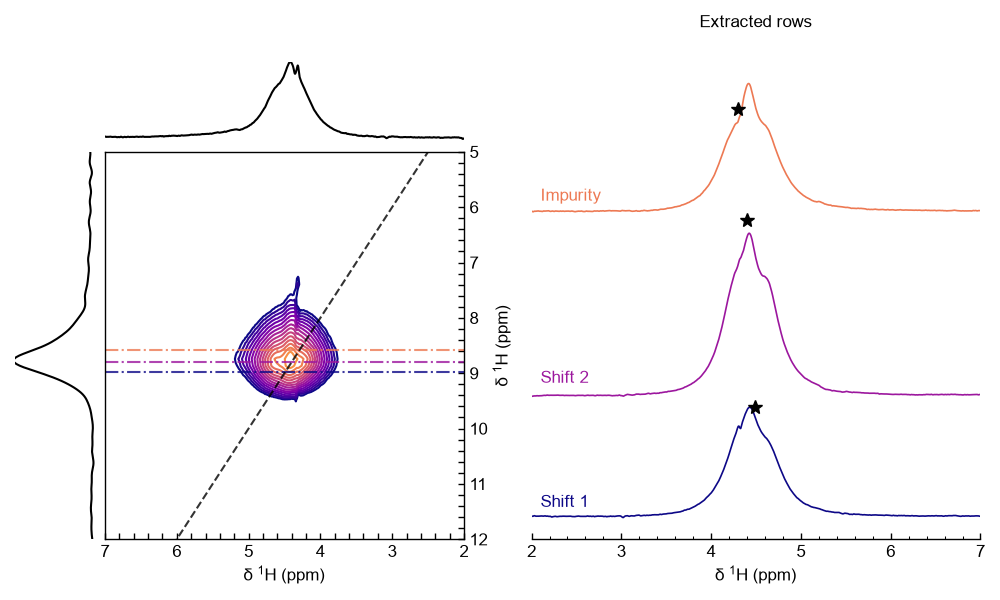

In [30]:
DQSQ = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_20260119\6", homonuclear=False)

fig, axes = nmr.NMR2D_summary_plot(
    DQSQ,
    pl_height=6.0, pl_width=10.0,
    slices=slices,
    slices_mode="rows",
    layout="grid",                               # "row" | "column" | "grid"
    clevels=20,
    factor=5e-2,
    colour_spectra="plasma",
    show_projections=True,                       # or 'f1', or 'f2' for single-axis projection
    projection_size=0.8,
    show_nQ_line=True,
    nQ=[2],                                      # single- and double-quantum diagonals
    nQ_colors=['black'],
    xlims=[7, 2], ylims=[12, 5],
    slices_on_contour_mode="rows",
    slices_on_contour_linestyle='-.',
    slices_on_contour_alpha=0.8,
    show_nQ_markers=True,
    nQ_marker_offset=0.1,
    show_labels=True,
    label_style='text',                          # 'text' or 'legend'
    labels=['Shift 1', 'Shift 2', 'Impurity'],
    label_fontsize='large',
    label_side='left',                           # 'left' or 'right'
    label_pad=0.05,                              # larger number: further away from spectrum
    save_fig=True,
    fig_name='Example_2d_with_slices',
    save_format='svg'
)

### 2.5 Plotting multiple 2-d datasets

<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
<>:8: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
C:\Users\quark\AppData\Local\Temp\ipykernel_15460\1542028907.py:8: SyntaxWarning: 

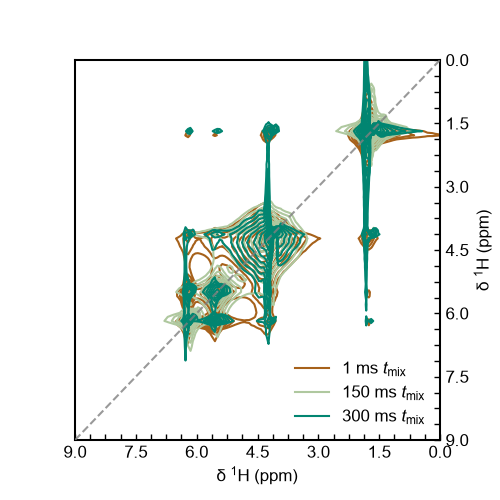

In [31]:
EXSY_1 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2261"
EXSY_2 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2262"
EXSY_3 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2263"

three_overlaid_exsys = nmr.NMR2D_overlay_plot([EXSY_1, EXSY_2, EXSY_3],
                                                xlims=[0, 9], ylims=[0, 9],
                                                pl_height=5, pl_width=5,
                                                labels=['1 ms $\mathit{t}_{\mathregular{mix}}$', '150 ms $\mathit{t}_{\mathregular{mix}}$', '300 ms $\mathit{t}_{\mathregular{mix}}$'],
                                                equal_tickspacing=True,
                                                legend_kwargs={"loc": 4, "frameon": False}, 
                                                show_nQ_line=True,
                                                nQ=[1],)
                                                #x_offsets=[0,0.5,1.0], y_offsets=[0,0.0,0.0],)

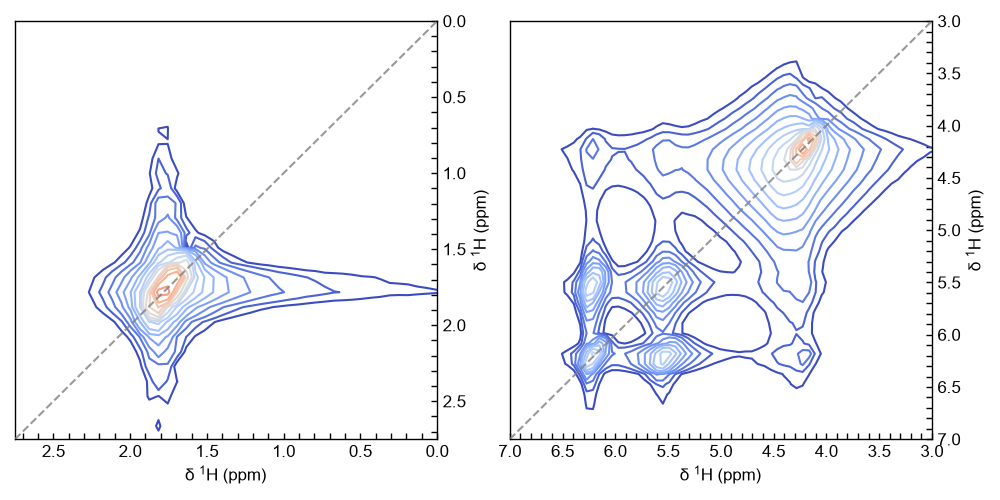

In [32]:
EXSY_1 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2261"
EXSY_2 = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_2H_23Na_113Cd_Na2CdFeCN6_D2O_150126A_VT_20260223\2262"

multi_2d_side_by_side = nmr.NMR2D_multi_plot([EXSY_1, EXSY_1], 
                                             layout="row", 
                                             panel_kwargs=[
                                                 {"xlims": [0.0, 2.75], "ylims": [0.0, 2.75], "show_nQ_line": True},
                                                 {"xlims": [3.0, 7.0], "ylims": [3.0, 7.0], "show_nQ_line": True}
                                             ],
                                             colour_spectra='coolwarm',
                                             show_projections=False)

## 3. Fit an imported 1-d spectrum

Define your peak model(s) — chemical shift, initial FWHM, and (for
pseudo-Voigt peaks) the Gaussian/Lorentzian mixing parameter `eta`.
Bounding the shift to a narrow window around the expected position is
strongly recommended: with no bounds, `curve_fit` is free to slide
overlapping peaks anywhere, which can converge to a degenerate,
physically meaningless solution. Quantities may also be fixed (not fitted).


NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.692844 ± 0.011131
  fwhm      = 7.617438 ± 0.024107
  amplitude = 16968155704.917402 ± 0.001772
  eta       = 0.350123 ± 0.006927
  integral (raw) = 153605652729.4409
  integral (%)    = 65.42

Peak 2 (pseudo-voigt):
  shift     = -0.005240 ± 0.011286
  fwhm      = 5.283234 ± 0.026498
  amplitude = 11128515685.187311 ± 0.002688
  eta       = 0.798988 ± 0.013951
  integral (raw) = 81186106803.0095
  integral (%)    = 34.58

Fit quality:
------------------------------------------------------------
RMSE          : 7.795543e+09
Chi^2         : 1.543571e+22
Reduced Chi^2 : 6.326109e+19

Optimised params from fit:  [-5.69284407e+00  7.61743814e+00  1.69681557e+10  3.50122710e-01
 -5.24027616e-03  5.28323385e+00  1.11285157e+10  7.98987820e-01
  9.57527424e-05  1.79673814e-09]
Covariance in optimised params:  [[ 1.23906501e-04  2.16397229e-04  7.32784718e-06 

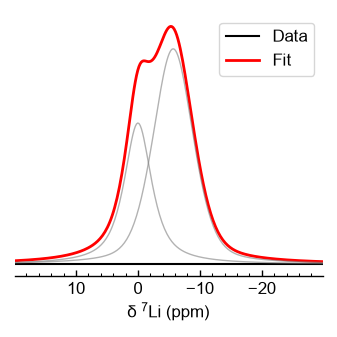

In [33]:
peak_defs = [
    {"type": "pseudo-voigt", "shift": -5.20, "fwhm": 5.0, "eta" : 0.5,
     "bounds": {"shift": (-6.0, -5.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)}},
    {"type": "pseudo-voigt", "shift": -0.52, "fwhm": 5.0, "eta" : 0.5,
     "bounds": {"shift": (0.5, -1.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)}},
]

#  Example with fixed peaks:

# peak_defs = [
#     {"type": "pseudo-voigt", "shift": -5.20, "fwhm": 5.0, "eta" : 0.5,
#      "bounds": {"shift": (-6.0, -5.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)},
#      "fixed": {"eta": True}},
#     {"type": "pseudo-voigt", "shift": -0.52, "fwhm": 5.0, "eta" : 0.5,
#      "bounds": {"shift": (0.5, -1.0), "fwhm" : (0.001, 10.0), "eta" : (0.0, 1.0)},
#      "fixed": {"eta": True}},
# ]

fit = nmr.NMRFitWorkflow(
    r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\1",
    peak_defs,
    procno=1,
    fit_regions=[(20, -30)],     # restrict the fit to this ppm window; None = whole spectrum
    show_plot=True,
    show_components=True,        # overlay individual peaks + baseline
    show_report=True,            # print fitted parameters, uncertainties, integrals
)

print("Optimised params from fit: ", fit["popt"])             # fitted parameters (shift, fwhm, amplitude[, eta] per peak, then b0, b1)
print("Covariance in optimised params: ", fit["pcov"])        # full covariance matrix
print("Components: ", fit["components"])                      # individual peak curves + baseline (last entry)

If you’d rather drive the lower-level pieces yourself (*e.g.* to reuse an
already-imported spectrum, or fit several regions differently):

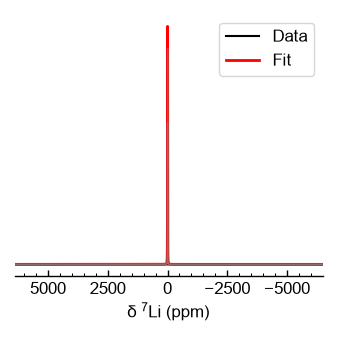

In [35]:
from opennmr.notebook.fitting import expand_pcov  # not re-exported at the top level -- see note below

spec = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\1")

popt, pcov_free, is_free, scale, x_ref = nmr.fit_spectrum(
    spec, peak_defs, fit_regions=[(20,-30)], use_normalised=True,
)
pcov = expand_pcov(pcov_free, is_free, len(popt))

y_fit, components = nmr.evaluate_fit(spec["x_ppm"], popt, peak_defs, x_ref=x_ref, return_components=True)
integrals, integrals_norm = nmr.compute_integrals(spec["x_ppm"], components)

fig, ax = nmr.NMR1dplot_with_fit(spec, popt, peak_defs, show_components=True)

Note: `expand_pcov`, `check_bound_hits`, `build_bounds`, and a few other
lower-level helpers aren’t re-exported at the package’s top level (only
the main entry points are, to keep `dir(nmrtools)` readable) — import
them from `nmrtools.fitting` directly if you need them, as above.

## 4. Fit rows extracted from a 2-d dataset and plot the integrals


2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 2.332337
  fwhm      = 7.700000 ± 4.438889
  amplitude = 511180.558725 ± 180642.324605
  eta       = 0.400000 ± 1.122673
  integral (raw) = 4986078.8150
  integral (%)    = 42.54

Peak 2 (pseudo-voigt):
  shift     = -0.290952 ± 0.792184
  fwhm      = 5.400000 ± 1.685791
  amplitude = 873627.043946 ± 315324.854663
  eta       = 0.717309 ± 0.851442
  integral (raw) = 6733696.6713
  integral (%)    = 57.46

Fit quality:
------------------------------------------------------------
RMSE          : 3.136429e+05
Chi^2         : 6.446900e+15
Reduced Chi^2 : 9.838691e+10


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6
-

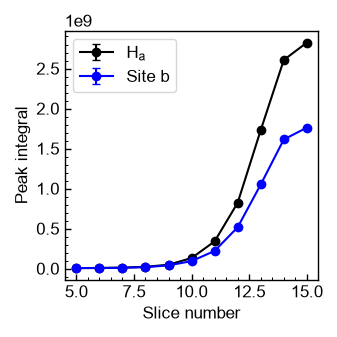

In [36]:
ds = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2")

slices = nmr.NMR2D_get_slices(ds, rows=list(range(5, 16)))   # rows 1-20
# or: nmr.NMR2D_get_slices(ds, row_shifts=[...])
# or, to fit every row: rows=nmr.select_2d_traces(ds, axis="f1", fit_all=True)

peak_defs = [
    {"type": "pseudo-voigt", "shift": -5.69, "fwhm": 7.62, "eta" : 0.35,
     "bounds": {"shift": (-5.58, -5.70), "fwhm" : (7.6, 7.7), "eta" : (0.3, 0.4)}},
    {"type": "pseudo-voigt", "shift": -0.005, "fwhm": 5.28, "eta" : 0.8,
     "bounds": {"shift": (0.5, -1.0), "fwhm" : (5.2, 5.4), "eta" : (0.7, 0.9)}},
]

fitted = nmr.NMR2D_fit_slices(
    slices,
    peak_defs,
    mode="rows",
    fit_regions=[(20,-30)],
    noise_region=(-150,-50),      # optional: peaks below sn_threshold here are fixed to 0
    sn_threshold=3,
    plot_integrals=False,       # we'll plot explicitly below for more control
    show_report=False,
    show_warnings=True,
)

print(fitted["rows"])                        # list of per-row fit results
print(fitted["rows"][0]["integrals"])        # this row's fitted peak area(s)
print(fitted["rows"][0]["integral_errors"])  # propagated from the amplitude uncertainty

fig, ax = nmr.NMR2D_plot_integrals(
    fitted["rows"],
    mode="rows",
    x_axis="shift",     # or "index"
    normalised=False,   # True -> each row's peaks normalised to 100%
    show_errors=True,
    peak_labels=[r'$\mathregular{H}_{a}$', 'Site b'],
    show_top_spine=True,
    show_right_spine=True,
    colors=['black', 'blue']
)

To also see the fitted curves overlaid on the extracted rows:

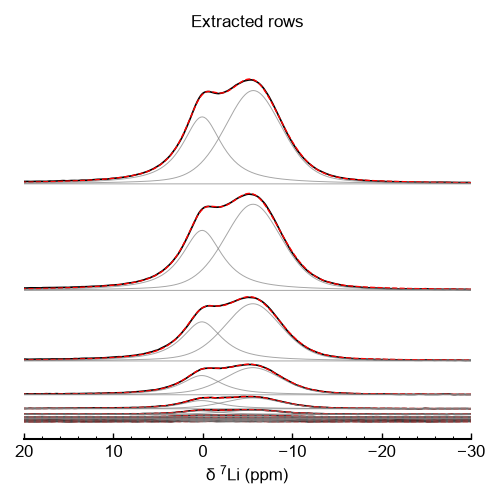

In [37]:
fig, ax = nmr.NMR2D_plot_slices(
    slices, mode="rows", fits=fitted["rows"],
    show_fits=True, show_fit_components=True,
    pl_width=5, pl_height=5,
    xlims=[20,-30]
)

Or combine the contour, fitted slices, and integrals in one figure:

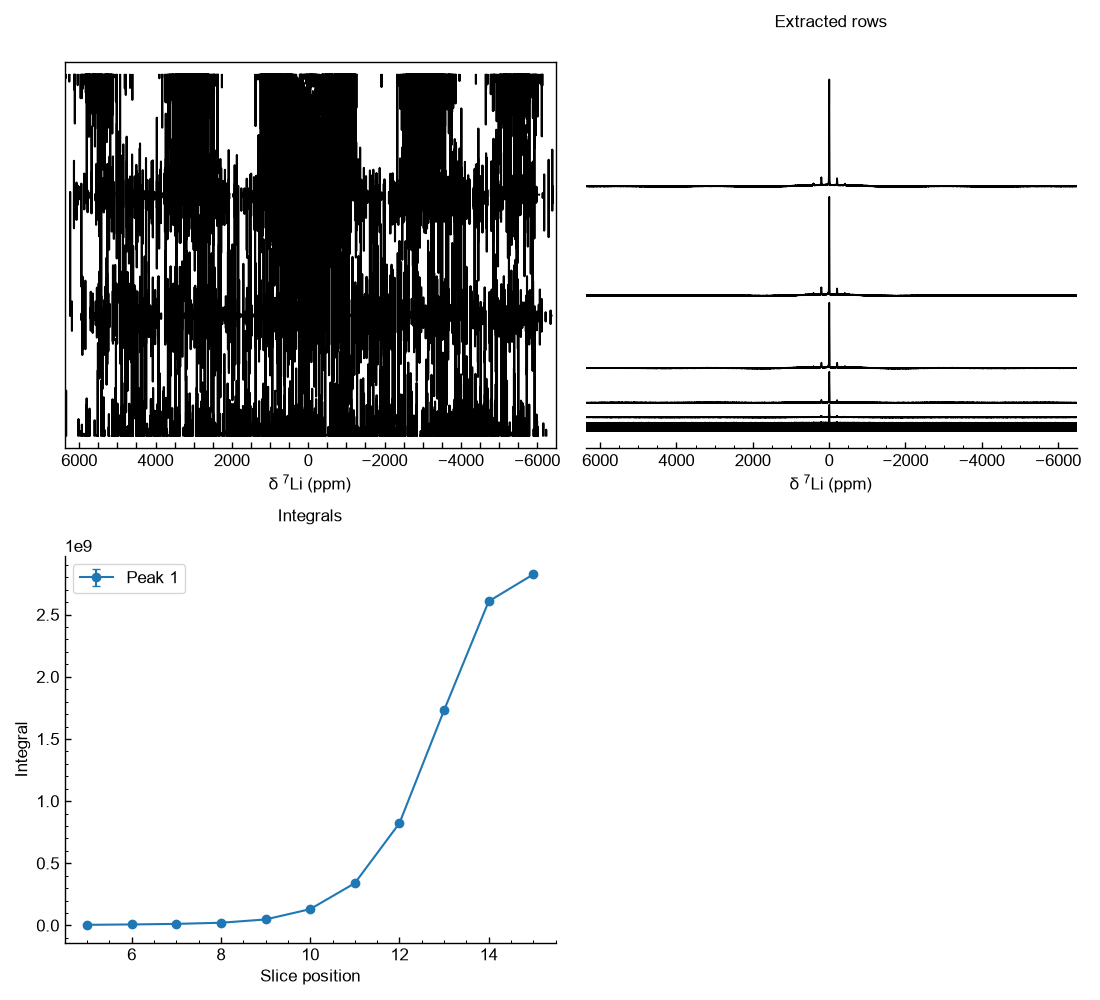

In [38]:
integral_curves = [{
    "x": [f["shift"] for f in fitted["rows"]],
    "y": [f["integrals"][0] for f in fitted["rows"]],
    "yerr": [f["integral_errors"][0] for f in fitted["rows"]],
    "label": "Peak 1",
}]

fig, axes = nmr.NMR2D_summary_plot(
    ds, slices=slices, fits=fitted["rows"], integrals=integral_curves,
    slices_mode="rows", layout="grid",
)

Or, all of the above in a single call:


2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 9.803828
  fwhm      = 7.600000 ± 15.358850
  amplitude = 218252.734280 ± 313366.498859
  eta       = 0.300000 ± 3.248408
  integral (raw) = 2017317.1845
  integral (%)    = 28.50

Peak 2 (pseudo-voigt):
  shift     = -1.000000 ± 1.340907
  fwhm      = 5.200000 ± 2.768374
  amplitude = 686068.806028 ± 652884.552246
  eta       = 0.700000 ± 1.490597
  integral (raw) = 5060989.2117
  integral (%)    = 71.50

Fit quality:
------------------------------------------------------------
RMSE          : 7.793583e+06
Chi^2         : 3.980653e+18
Reduced Chi^2 : 6.074921e+13


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6


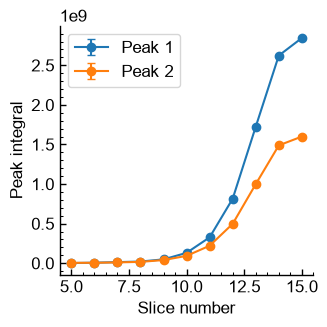

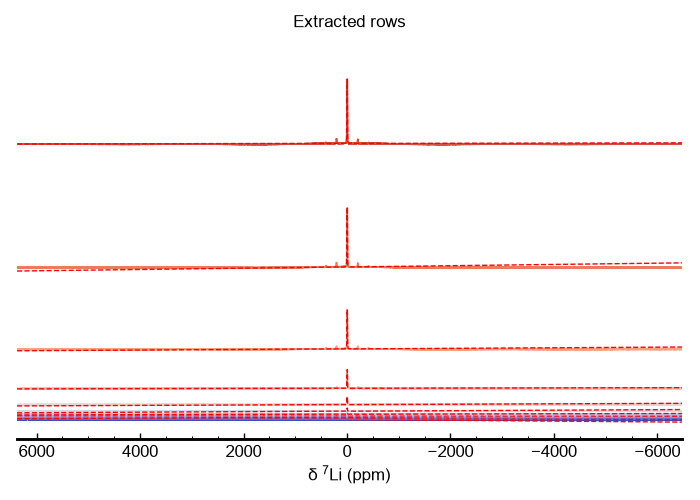

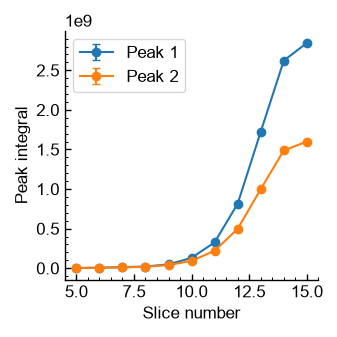

In [39]:
out = nmr.NMR2D_workflow(
    r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2",
    peak_defs=peak_defs,
    rows=list(range(5, 16)),
    fit_regions=[(20,-30)],
    baseline_regions=[(-150,-50)],
    normalize=False,
    show_slices=True, show_fits=True, show_integrals=True,
    show_report=False, show_warnings=True
)

out["rows"]["slices"]           # extracted traces
out["rows"]["fits"]             # fit results, same schema as NMR2D_fit_slices output
out["rows"]["figure"]           # the extracted-slices plot
out["rows"]["integral_figure"]  # the integrals plot

## 5. Fit relaxation curves (T1 / T2 / T1rho) from a 2-d dataset

`nmrtools.relaxation` fits a named model (see
`nmrtools.relaxation.RELAXATION_MODELS`) to each peak's integral series
across a pseudo-2D relaxation experiment:

```
NMR2D_get_slices -> [NMR2D_fit_slices | NMR2D_integrate_slices]
                  -> NMR2D_fit_relaxation -> NMR2D_plot_relaxation
```

or all of that in one call with `NMR2D_relaxation_workflow`. Delay times
are read automatically from the dataset's Bruker `vdlist` unless you
pass one explicitly.

Available models: `saturation_recovery`, `inversion_recovery` (T1);
`exponential_decay` (T2, or T1rho from a spin-lock decay); their
`biexponential_*` counterparts for two resolvable components; and
`stretched_decay`/`stretched_recovery` (Kohlrausch-Williams-Watts) for a
distribution of relaxation times. T1rho experiments reuse the T1/T2
functional forms -- just relabel the reported rate constant yourself.


### 5.1 End-to-end with `NMR2D_relaxation_workflow`

As with `NMR2D_workflow`, this drives the whole pipeline in one call.
`annotate=True` labels each fitted curve directly on the plot with its
rate constant; `colors` sets each series' data-point colour (the fit
curve is automatically drawn as a paler shade of the same colour, so
the two stay visually tied). `annotate_position`, `annotate_offset` and
`annotate_ha`/`annotate_va` control exactly where each label sits --
either a single value applied to every series, or a list with one entry
per series (in the order given, after any `show_series` filtering).



2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 9.803828
  fwhm      = 7.600000 ± 15.358850
  amplitude = 218252.734280 ± 313366.498859
  eta       = 0.300000 ± 3.248408
  integral (raw) = 2017317.1845
  integral (%)    = 28.50

Peak 2 (pseudo-voigt):
  shift     = -1.000000 ± 1.340907
  fwhm      = 5.200000 ± 2.768374
  amplitude = 686068.806028 ± 652884.552246
  eta       = 0.700000 ± 1.490597
  integral (raw) = 5060989.2117
  integral (%)    = 71.50

Fit quality:
------------------------------------------------------------
RMSE          : 7.793583e+06
Chi^2         : 3.980653e+18
Reduced Chi^2 : 6.074921e+13


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6


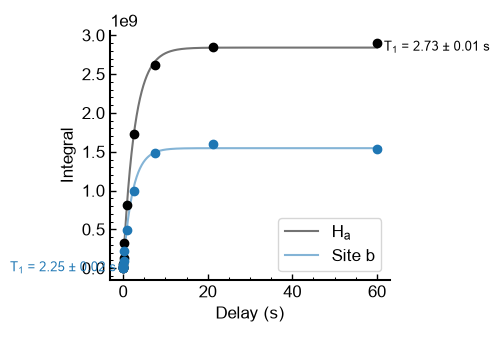

In [40]:
peak_defs = [
    {"type": "pseudo-voigt", "shift": -5.69, "fwhm": 7.62, "eta" : 0.35,
     "bounds": {"shift": (-5.58, -5.70), "fwhm" : (7.6, 7.7), "eta" : (0.3, 0.4)}},
    {"type": "pseudo-voigt", "shift": -0.005, "fwhm": 5.28, "eta" : 0.8,
     "bounds": {"shift": (0.5, -1.0), "fwhm" : (5.2, 5.4), "eta" : (0.7, 0.9)}},
]

fitted_satrec = nmr.NMR2D_relaxation_workflow(
    r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2",
    peak_defs=peak_defs,
    rows=list(range(5, 17)),
    fit_regions=[(20, -30)],
    baseline_regions=[(-150, -50)],
    show_report=True,
    normalize=False,
    model='saturation_recovery',
    peak_labels=[r'$\mathregular{H}_{a}$', 'Site b'],
    annotate=True,                        # label each curve with its fitted T1
    colors=['black', 'tab:blue'],          # one data colour per peak
    annotate_position=['end', 'start'],    # per-series label placement along the curve
    annotate_offset=[(5, 0), (-5, 0)],     # (dx, dy) in points, per series
    annotate_ha=['left', 'right'],
    pl_width=5.0,
    show_top_spine=False, show_right_spine=False,
    logplot=False,
)

print(fitted_satrec["relaxation_fits"][0]["params"])  # fitted M0, T1 for peak 1


### 5.2 Driving it manually, for finer control

Useful for trying several models against the same fitted slices without
re-fitting the peaks each time, or for tuning colours/label placement
after seeing a first draft. `colors`, `fit_colors`, `fit_shade`,
`annotate_position`, `annotate_offset`, `annotate_ha` and `annotate_va`
are all exposed directly on `NMR2D_plot_relaxation`:



2D NMR SLICE REPORT | slice 5
Slice position: 5.00000 ppm

NMR FIT REPORT

Peak parameters:
------------------------------------------------------------

Peak 1 (pseudo-voigt):
  shift     = -5.580000 ± 9.803828
  fwhm      = 7.600000 ± 15.358850
  amplitude = 218252.734280 ± 313366.498859
  eta       = 0.300000 ± 3.248408
  integral (raw) = 2017317.1845
  integral (%)    = 28.50

Peak 2 (pseudo-voigt):
  shift     = -1.000000 ± 1.340907
  fwhm      = 5.200000 ± 2.768374
  amplitude = 686068.806028 ± 652884.552246
  eta       = 0.700000 ± 1.490597
  integral (raw) = 5060989.2117
  integral (%)    = 71.50

Fit quality:
------------------------------------------------------------
RMSE          : 7.793583e+06
Chi^2         : 3.980653e+18
Reduced Chi^2 : 6.074921e+13


Warnings:
------------------------------------------------------------
Peak 1 shift near upper bound -5.58
----
Peak 1 shift near lower bound -5.7
----
Peak 1 fwhm near upper bound 7.7
----
Peak 1 fwhm near lower bound 7.6


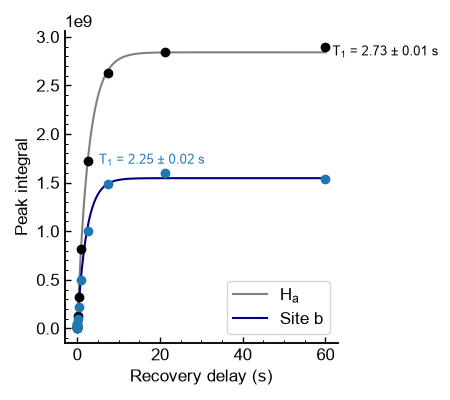

In [41]:
ds = nmr.NMR2dimport(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2")
slices = nmr.NMR2D_get_slices(ds, rows=list(range(5, 17)))

fitted = nmr.NMR2D_fit_slices(
    slices, peak_defs, mode="rows",
    fit_regions=[(20, -30)], baseline_regions=[(-150, -50)],
    show_report=False, show_warnings=True,
)

relax_fits = nmr.NMR2D_fit_relaxation(
    fitted["rows"], model="saturation_recovery",
    peak_labels=[r'$\mathregular{H}_{a}$', 'Site b'],
    use_errors=True,   # weight the fit by each slice's propagated integral error
    show_report=True,
)

fig, ax = nmr.NMR2D_plot_relaxation(
    relax_fits,
    annotate=True,
    colors=['black', 'tab:blue'],     # data-point colour per series
    fit_colors=[None, 'navy'],        # None -> auto pale tint of the data colour; override just Site b
    fit_shade=0.5,                    # paleness of the *automatic* fit curves (ignored where fit_colors is set)
    annotate_position=['end', 0.3],   # 'start' / 'middle' / 'end', or a 0-1 fraction along the curve
    annotate_offset=[(5, 0), (0, 8)],
    annotate_ha=['left', 'center'],
    annotate_va=['center', 'bottom'],
    xlabel="Recovery delay (s)", ylabel="Peak integral",
    pl_width=4.5, pl_height=4.0,
)


Delays come from the dataset's own `vdlist` by default (resolved from
`fitted["rows"]`). Pass one explicitly -- a Bruker experiment path, the
dict from `read_vdlist`, or a plain array of seconds (1-based F1 index)
-- if the pseudo-2D wasn't acquired with a Topspin `vdlist`, or to
override it:


In [42]:
vd = nmr.read_vdlist(r"C:\Users\quark\OneDrive\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2")

relax_fits = nmr.NMR2D_fit_relaxation(fitted["rows"], model="saturation_recovery", vdlist=vd)
# or: vdlist=r"...\2"                         (a Bruker experiment path)
# or: vdlist=[0.001, 0.01, 0.1, 1.0, 5.0, ...]  (seconds, one per slice)



--- Peak 1 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 2.84118e+09 ± 7.424e+06
  T1      = 2.73152 ± 0.01354

  T1 = 2.73 ± 0.01 s

  RMSE          = 2.307e+07
  Reduced chi^2 = 21.51


--- Peak 2 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 1.54596e+09 ± 8.959e+06
  T1      = 2.24984 ± 0.02436

  T1 = 2.25 ± 0.02 s

  RMSE          = 2.778e+07
  Reduced chi^2 = 26.17



### 5.3 Region-based integration, when individual peaks aren't resolved

If peaks are too overlapping/poorly resolved to be worth fitting,
integrate bulk regions instead with `NMR2D_integrate_slices` -- its
output is shaped closely enough to `NMR2D_fit_slices`'s that it drops
straight into `NMR2D_fit_relaxation` in place of a fitted-peaks series:


In [43]:
region_series = nmr.NMR2D_integrate_slices(
    slices, regions=[[3.4, 4.5], [4.5, 8.0]], mode="rows",
    region_labels=["Region 1", "Region 2"],
    subtract_baseline=True, baseline_regions=[(-150, -50)],
)

relax_fits_regions = nmr.NMR2D_fit_relaxation(
    region_series["rows"], model="saturation_recovery",
    peak_labels=["Region 1", "Region 2"],
)



--- Region 1 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 6.29104e+07 ± 1.059e+06
  T1      = 2.49842 ± 0.1664

  T1 = 2.50 ± 0.17 s

  RMSE          = 1.616e+06
  Reduced chi^2 = 0.1294


--- Region 2 ---

RELAXATION FIT REPORT (saturation_recovery)
  M0      = 1.30699e+08 ± 2.295e+06
  T1      = 2.35966 ± 0.1602

  T1 = 2.36 ± 0.16 s

  RMSE          = 5.771e+06
  Reduced chi^2 = 0.1918



### 5.4 Fitting an arbitrary `(t, y)` array directly

`fit_relaxation` isn't tied to 2-d datasets at all -- fit any delay/
intensity series directly, e.g. integrals you've already extracted by
some other route:


In [44]:
import numpy as np

t = np.array([0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0])
y = np.array([120, 480, 800, 1850, 2400, 2700, 2820])

fit = nmr.fit_relaxation(t, y, model="saturation_recovery")
nmr.print_relaxation_report(fit)

# format_time_value auto-picks a sensible unit (s/ms/us/ns) for display
print(nmr.format_time_value(fit["params"]["T1"], fit["errors"]["T1"]))



RELAXATION FIT REPORT (saturation_recovery)
  M0      = 2717.03 ± 94.45
  T1      = 0.394782 ± 0.054

  T1 = 395 ± 54 ms

  RMSE          = 116.7
  Reduced chi^2 = 1.906e+04

395 ± 54 ms


The same `rows=` -> `columns=` swap works throughout (`NMR2D_get_slices`,
`NMR2D_relaxation_workflow`) if what you actually want is column
extraction/fitting (*e.g.* a T1 buildup along F1 at a fixed F2 shift)
instead of rows.


## 6. Modelling and Simulating Chemical Shift Anisotropy

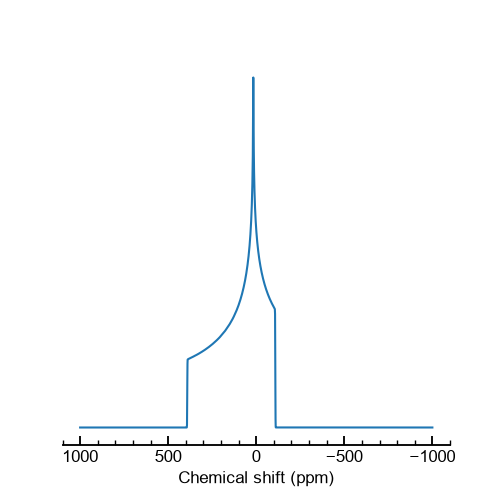

In [45]:
csa_example = nmr.csa_definition(100, 500, 0.5, convention='Herzfeld-Berger')

spec = nmr.make_static_csa_spectrum(csa_example, np.linspace(-1000, 1000, 5001))


#######

fig, ax = plt.subplots(figsize=(5,5))

ax.plot(spec['x_ppm'], spec['real_spec'], '-')

ax.set_xlabel("Chemical shift (ppm)")
ax.yaxis.set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.invert_xaxis()

plt.show()

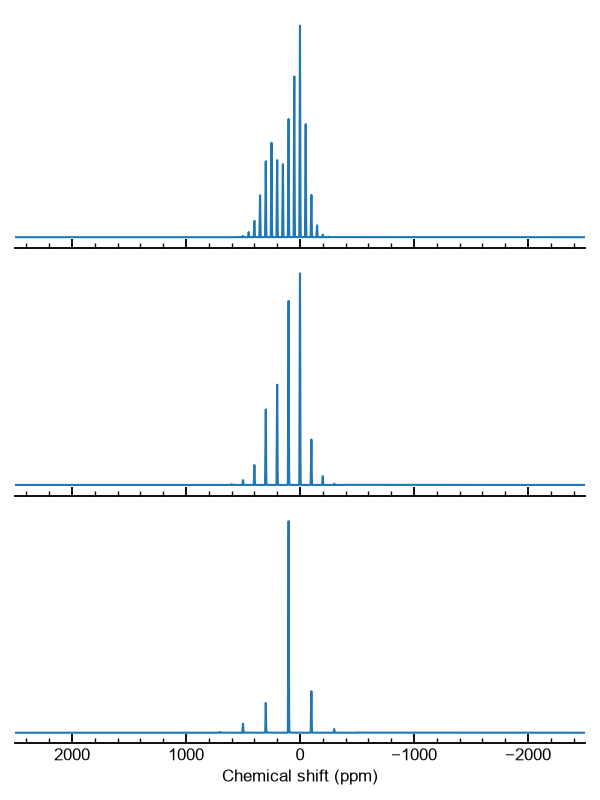

In [46]:
mas_rates = [25000, 50000, 100000]
csa_example = nmr.csa_definition(100, 500, 0.5, convention='Herzfeld-Berger')

fig, axes = plt.subplots(3, 1, figsize=(6, 8), sharex=True)

for ax, mas_Hz in zip(axes, mas_rates):

    spectrum = nmr.finite_mas_csa_spectrum(csa_example, np.linspace(-10000,10000,50001), larmor_Hz=500e6, mas_Hz=mas_Hz,
                                        n_theta=30, n_phi=60, n_time=4096, n_sidebands=100, fwhm=5.0,)

    ax.plot(spectrum['x_ppm'], spectrum['real_spec'], '-')

    ax.set_ylabel(f"{mas_Hz/1000:g} kHz")

    ax.set_xlim([-2500, 2500])
    ax.invert_xaxis()
    ax.yaxis.set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

axes[-1].set_xlabel(
    "Chemical shift (ppm)"
)


plt.tight_layout()
plt.show()

## 7. Fitting Chemical Shift Anisotropy

In [2]:
nmr.NMRCSAFitWorkflow?

Signature:
nmr.NMRCSAFitWorkflow(
    datapath,
    p0,
    procno=1,
    convention='Haeberlen',
    static=True,
    larmor_Hz=None,
    mas_Hz=None,
    rotor_angle='magic',
    n_theta=60,
    n_phi=120,
    use_octant_symmetry=True,
    n_time=1024,
    n_sidebands=15,
    subtract_residual_mean=True,
    fit_regions=None,
    baseline_regions=None,
    baseline_sigma=2.5,
    baseline_max_iter=10,
    normalize=True,
    bounds=None,
    fixed=None,
    positive_intensity=True,
    allow_negative_intensity=False,
    show_plot=True,
    xlims='default',
    xlabel=None,
    pl_width=3.375,
    pl_height=3.375,
    font='Arial',
    fontsize=12,
    output_format='',
    tick_dir='in',
    tick_length=4.0,
    tick_width=1.0,
    tick_pad=4.0,
    tick_number=None,
    show_components=False,
    show_report=True,
    save_csv=False,
    csv_filename='csa_fit_results.csv',
    save_report=False,
    report_filename='csa_fit_report.txt',
    save_fig=False,
    fig_name='nmr_csa_fit


CSA FIT REPORT (Haeberlen convention)

Parameters:
------------------------------------------------------------
  d_iso       = 0.340258 ± 0.000142
  Delta       = -109.900279 ± 0.238191
  eta         = 0.909583 ± 0.008207
  fwhm        = 0.688804 ± 0.000275
  amplitude   = 48173851264.348557 ± 0.000000
  b0          = -56716373.330496 (fixed)
  b1          = -168.849047 (fixed)

Fit quality:
------------------------------------------------------------
RMSE          : 9.874611e+07
Chi^2         : 1.298211e+21
Reduced Chi^2 : 9.751307e+15



{'popt': array([ 3.40257813e-01, -1.09900279e+02,  9.09582617e-01,  6.88803786e-01,
         4.81738513e+10, -5.67163733e+07, -1.68849047e+02]),
 'pcov': array([[ 2.02849960e-08, -5.91021085e-08, -1.84320953e-10,
          8.50769430e-10,  4.10267274e-17,  0.00000000e+00,
          0.00000000e+00],
        [-5.91021085e-08,  5.67349813e-02,  1.72709195e-03,
          2.73065515e-06, -3.93785200e-11,  0.00000000e+00,
          0.00000000e+00],
        [-1.84320953e-10,  1.72709195e-03,  6.73605721e-05,
         -2.26330694e-09, -1.19872935e-12,  0.00000000e+00,
          0.00000000e+00],
        [ 8.50769430e-10,  2.73065515e-06, -2.26330694e-09,
          7.58515760e-08, -1.89462844e-15,  0.00000000e+00,
          0.00000000e+00],
        [ 4.10267274e-17, -3.93785200e-11, -1.19872935e-12,
         -1.89462844e-15,  2.73317766e-20,  0.00000000e+00,
          0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  0.000000

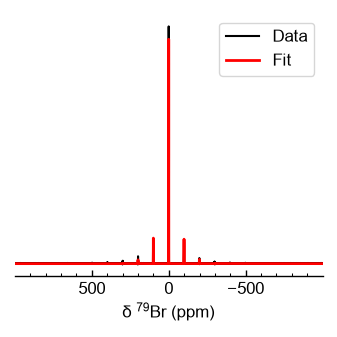

In [17]:
# KBr reference spectrum, 79Br, 2.5 mm HX probe, VT, 800 MHz
spec_to_fit = r"C:\Users\quark\OneDrive\Documents\NMR\800_NB_MHz_Lyon\2p5mm_HX_79Br_KBr_ref_VT_20260226\2"

peak_defs = {"d_iso": 0.34, "span_or_Delta": -109.9, "skew_or_eta": 0.909, "fwhm": 0.688,
             "fixed": {"d_iso": False, "span_or_Delta": True, "skew_or_eta": True, "fwhm": True},}

nmr.NMRCSAFitWorkflow(
    spec_to_fit,
    p0=peak_defs,
    static=False,
    normalize=False,
    larmor_Hz=None,
    mas_Hz=20000,
    fit_regions=[(-1000, 1000)],
    show_plot=True,
    show_report=True,
)

## 8. pNMR Simulator: Bond Pathways

### 8.1 (Optional) inspect the raw neighbor-distance distribution first

This helps you choose sensible shell boundaries (`shell_bins`) before
committing to them below — look for the gaps in the sorted distances.

In [47]:
cif_filename = r"C:\Users\quark\OneDrive\Documents\Neutron\LIRO_Combined_Refinement\Refinement_Results_20250122\CIF_LRMO_C2m_disord.cif"

structure, site_data = nmr.read_cif_with_occupancies(
    cif_filename, atom_of_interest="Li", verbose=True
)

d = nmr.shell_distance_histogram(
    structure, site_data, "Li", max_r=6.0, ignore_species=["O", "O2-"]
)
# np.diff(d) will show the gaps that should become your shell boundaries
print(d[:20])

[2.71457736 2.71457736 2.71457736 2.71457736 2.71457736 2.71457736
 2.71457736 2.71457736 2.74773054 2.74773054 2.74773054 2.74773054
 2.74773054 2.74773054 2.74773054 2.74773054 2.85401211 2.85401211
 2.85401211 2.85401211]


c:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\pnmr_simulator.py:65: UserWarning: Issues encountered while parsing CIF: 3 fractional coordinates rounded to ideal values to avoid issues with finite precision.
Skipping relative stoichiometry check because CIF does not contain formula keys.
  structures = parser.parse_structures(primitive=False)


### 8.2 Define shells, shift contributions, and nuclide/field, then simulate

- `shell_bins`: coordination shells around the site of interest, e.g. NN / NNN.
- `shift_dict`: ppm contribution per neighbor species, per shell. Species not
  listed (and vacancies, `'Va'`) contribute 0 by convention.
- `nuclide` / `B0_tesla`: used only for ppm<->Hz referencing (`BF1`, `SFO1`);
  independent of `atom_of_interest`, which is the *structural* site label.

In [ ]:
shell_bins = [
    ("NN",  0.0, 3.10),
    ("NNN", 3.50, 4.20),
]

shift_dict = {
    "NN":  {"Mn": 250,  "Ru": -10, "Li": 0.0},
    "NNN": {"Mn": -60, "Ru": -3,  "Li": 0.0},
}

spectrum_dict, shift_table = nmr.generate_spectrum_dict(
    cif_filename=cif_filename,
    atom_of_interest="Li",
    shell_bins=shell_bins,
    shift_dict=shift_dict,
    ignore_species=["O", "O2-"],
    nuclide="7Li",
    B0_tesla=9.4,          # simulated/target spectrometer field, in Tesla
    broadening=1.0,        # Gaussian sigma, ppm
    xlims=[-1000, 2800],
    output_dir=None,       # defaults to <cif dir>/pnmr_simulation
    verbose=True,
)

print(spectrum_dict.keys())
print("nuclide:", spectrum_dict["nuclide"])
print("BF1 (MHz):", spectrum_dict["BF1"], " SFO1 (MHz):", spectrum_dict["SFO1"])
print("shift table + spectrum dict saved under:", spectrum_dict["path"])

shift_table.head()

dict_keys(['x_ppm', 'x_Hz', 'real_spectrum', 'normalised_real_spectrum', 'imag_spectrum', 'normalised_imag_spectrum', 'nuclide', 'BF1', 'SFO1', 'path'])
nuclide: 7Li
BF1 (MHz): 155.55543  SFO1 (MHz): 155.55543
shift table + spectrum dict saved under: C:\Users\quark\OneDrive\Documents\Neutron\LIRO_Combined_Refinement\Refinement_Results_20250122\pnmr_simulation


,Site,Config,NN_Li,NN_Ru,NNN_Ru,Total_shift,p,NNN_Mn,NNN_Li,NN_Mn
0,0,0,5,6.0,4.0,-72.0,0.000001,0.0,0.0,0.0
1,0,1,5,6.0,3.0,-129.0,0.000004,1.0,0.0,0.0
2,0,2,5,6.0,3.0,-69.0,0.000014,0.0,1.0,0.0
3,0,3,5,6.0,2.0,-186.0,0.000004,2.0,0.0,0.0
4,0,4,5,6.0,2.0,-126.0,0.000032,1.0,1.0,0.0


### 8.3 Plot the simulated spectrum on its own

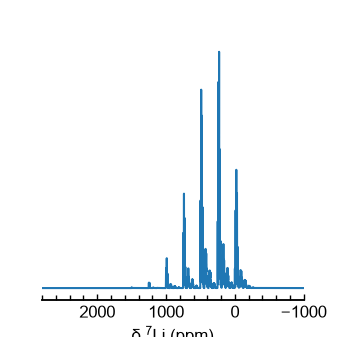

In [49]:
ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True)
plt.show()
plt.tight_layout()

### 8.4 Compare against an experimental spectrum

Load (or already have) an experimental spectrum in the same dict shape —
e.g. from your Bruker-processing pipeline — and overlay it.

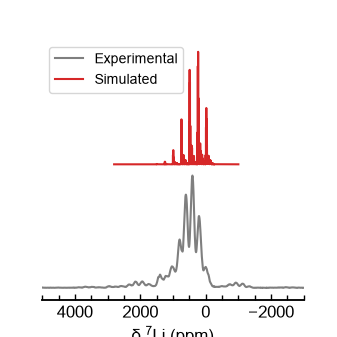

In [ ]:
# experimental_dict = load_your_experimental_spectrum(...)
# Must have the same keys as spectrum_dict above.

experimental_dict = nmr.NMR1dimport(r"C:\Users\quark\OneDrive\Documents\NMR\100MHz_UCSB\100_ENB_20230807_Li2Ru0p5Mn0p5O3_300123A_Pristine_7Li\991000")

ax = nmr.plot_comparison(spectrum_dict, experimental_dict, axis="ppm", channel="real", offset = 1.1)
ax.set_xlim([5000, -3000])
plt.show()
plt.tight_layout()

### 8.5 More complex example

[{'site_index': 0, 'coordinates': array([0., 0., 0.]), 'occupancies': [{'species': 'Na+', 'probability': 1.0}], 'contains Na+': True}, {'site_index': 1, 'coordinates': array([1.488615  , 0.85945227, 5.36493333]), 'occupancies': [{'species': 'Na+', 'probability': 1.0}], 'contains Na+': True}, {'site_index': 2, 'coordinates': array([2.22044605e-16, 1.71890454e+00, 1.07298667e+01]), 'occupancies': [{'species': 'Na+', 'probability': 1.0}], 'contains Na+': True}, {'site_index': 3, 'coordinates': array([0.    , 0.    , 8.0474]), 'occupancies': [{'species': 'Ni2+', 'probability': 0.25}, {'species': 'Mn3+', 'probability': 0.3}, {'species': 'Mn4+', 'probability': 0.2}, {'species': 'Fe3+', 'probability': 0.25}], 'contains Na+': False}, {'site_index': 4, 'coordinates': array([ 1.488615  ,  0.85945227, 13.41233333]), 'occupancies': [{'species': 'Ni2+', 'probability': 0.25}, {'species': 'Mn3+', 'probability': 0.3}, {'species': 'Mn4+', 'probability': 0.2}, {'species': 'Fe3+', 'probability': 0.25}], 

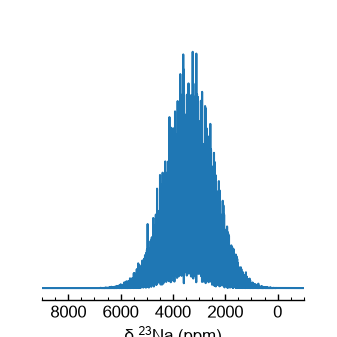

In [3]:
# "C:\Users\quark\OneDrive\Documents\Calculations\Pedro_Na_O3_Cathode\CIF_O3_NaNiMnFe_based_on_EntryWithCollCode19572.cif"

cif_filename = r"C:\Users\quark\OneDrive\Documents\Calculations\Pedro_Na_O3_Cathode\CIF_O3_NaNiMnFe_with_charges_based_on_EntryWithCollCode19572.cif"

structure, site_data = nmr.read_cif_with_occupancies(
    cif_filename, atom_of_interest="Na+", verbose=True
)

print(site_data)

d = nmr.shell_distance_histogram(
    structure, site_data, "Na+", max_r=6.0, ignore_species=["O", "O2-"]
)
# np.diff(d) will show the gaps that should become your shell boundaries
print(d[:20])

shell_bins = [
    ("NN",  0.0, 3.20),
    ("NNN", 3.80, 4.40),
]

shift_dict = {
    "NN":  {"Ni2+": -68, "Mn3+": 246, "Mn4+": 460, "Fe3+": 45, "Na+": 0.0},
    "NNN": {"Ni2+": 300, "Mn3+": 440, "Mn4+": -34, "Fe3+": 800, "Na+": 0.0},
}

spectrum_dict, shift_table = nmr.generate_spectrum_dict(
    cif_filename=cif_filename,
    atom_of_interest="Na+",
    shell_bins=shell_bins,
    shift_dict=shift_dict,
    ignore_species=["O", "O2-"],
    nuclide="23Na",
    B0_tesla=11.7,          # simulated/target spectrometer field, in Tesla
    broadening=1.0,        # Gaussian sigma, ppm
    xlims=[-1000, 9000],
    output_dir=None,       # defaults to <cif dir>/pnmr_simulation
    verbose=True,
)

print(spectrum_dict.keys())
print("nuclide:", spectrum_dict["nuclide"])
print("BF1 (MHz):", spectrum_dict["BF1"], " SFO1 (MHz):", spectrum_dict["SFO1"])
print("shift table + spectrum dict saved under:", spectrum_dict["path"])

shift_table.head()

ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True)
plt.show()
plt.tight_layout()

We can also plot the shifts as a function of local composition, to make sense of the local interactions

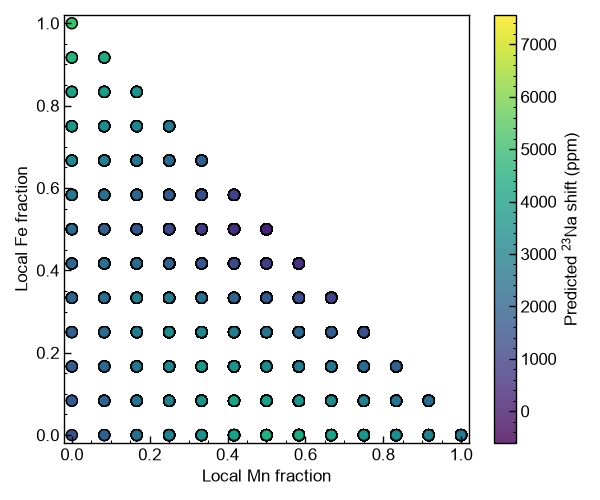

In [15]:
df = shift_table.copy()

# Total number of magnetic/transition-metal neighbours
tm_cols = [
    "NN_Ni2+", "NN_Mn4+", "NN_Mn3+", "NN_Fe3+",
    "NNN_Ni2+", "NNN_Mn4+", "NNN_Mn3+", "NNN_Fe3+",
]

df["TM_total"] = df[tm_cols].sum(axis=1)

df["Mn_fraction"] = (
    df["NN_Mn3+"] + df["NNN_Mn3+"] + df["NN_Mn4+"] + df["NNN_Mn4+"]
) / df["TM_total"]

df["Fe_fraction"] = (
    df["NN_Fe3+"] + df["NNN_Fe3+"]
) / df["TM_total"]

fig, ax = plt.subplots(figsize=(6, 5))

sc = ax.scatter(
    df["Mn_fraction"],
    df["Fe_fraction"],
    c=df["Total_shift"],
    s=60, #1000 * df["p"],
    cmap="viridis",
    edgecolor="k",
    alpha=0.8,
)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Predicted $^{23}$Na shift (ppm)")

ax.set_xlabel("Local Mn fraction")
ax.set_ylabel("Local Fe fraction")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)

plt.tight_layout()
plt.show()

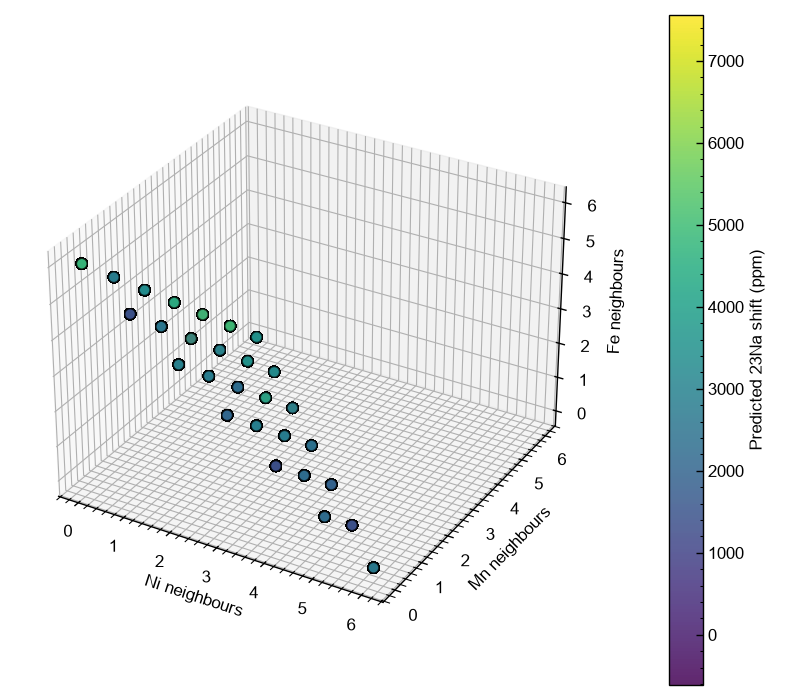

In [16]:
df = shift_table.copy()

# Combine NN and NNN neighbours
df["Ni_NN"] = df["NN_Ni2+"] #+ df["NNN_Ni2+"]
df["Mn_NN"] = df["NN_Mn3+"] + df["NN_Mn4+"] #+ df["NNN_Mn3+"] + df["NNN_Mn4+"] 
df["Fe_NN"] = df["NN_Fe3+"] #+ df["NNN_Fe3+"]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df["Ni_NN"],
    df["Mn_NN"],
    df["Fe_NN"],
    c=df["Total_shift"],
    s= 60, #1500 * df["p"],
    cmap="viridis",
    edgecolor="k",
    alpha=0.85,
)

ax.set_xlabel("Ni neighbours")
ax.set_ylabel("Mn neighbours")
ax.set_zlabel("Fe neighbours")

cbar = fig.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("Predicted 23Na shift (ppm)")

plt.tight_layout()
plt.show()

## 9. BMS Simulation: predicting Bulk Magnetic Susceptibility shifts from a particle packing

The `bms` sub-package predicts the NMR shift caused by the bulk magnetic
susceptibility (BMS) of a packing of anisotropic particles -- e.g. platelets
or needles of a magnetic phase dispersed in a diamagnetic matrix. Given the
particles' positions, sizes/shapes, orientations, and principal-axis
magnetic susceptibility, it computes the demagnetizing field on a 3-d grid,
converts that into a bulk-susceptibility shift tensor at every grid point,
and (optionally) turns the resulting distribution of shifts into a
MAS-spinning-sideband-broadened lineshape.

The top-level, recommended entry point is `nmr.generate_bms_spectrum_dict`,
which returns the same 10-key `spectrum_dict` as every other spectrum in
`opennmr` (`x_ppm`, `real_spectrum`, `normalised_real_spectrum`, ...) --
so a BMS-predicted lineshape plots and overlays with an experimental one
using the exact same `plot_spectrum_dict`/`plot_comparison` functions from
Section 1, no BMS-specific plotting code required.

The lower-level pieces it's built from (`run_bms`, `run`, `build_box`,
`particles_to_array`, `assemble_spectrum`, ...) aren't re-exported at the
top level -- import them from `opennmr.notebook.bms` directly, as shown in
9.5-9.8 below, if you want the per-voxel table without a spectrum, or want
to drive an individual step yourself.

### 9.1 Build particles with `make_particle`

`make_particle(x, y, z, size, quaternion=(1,0,0,0), id=None)` builds one
particle record -- no LAMMPS dump file required. `size` is a 3-tuple whose
meaning depends on the `equation` you pass to the simulation call below:

| `equation`   | `size` meaning                          |
|--------------|------------------------------------------|
| `"ellipsoid"`| (semi-axis-x, semi-axis-y, semi-axis-z)  |
| `"hexagonal"`| (hex radius, unused, height)             |
| `"donut"`    | (major radius R0, minor radius r0, unused)|

`quaternion` is `(qw, qx, qy, qz)` (scalar-first, needn't be pre-normalized);
the default `(1,0,0,0)` is "no rotation".

In [14]:
particles = [
    nmr.make_particle(x=0,   y=0, z=0, size=(60, 60, 10)),
    nmr.make_particle(x=150, y=0, z=0, size=(60, 60, 10),
                       quaternion=(0.707, 0.707, 0, 0)),   # tilted 90 deg about x
    nmr.make_particle(x=-150, y=0, z=0, size=(60, 60, 10)),
]
particles

[{'id': None,
  'x': 0,
  'y': 0,
  'z': 0,
  'v1': 60,
  'v2': 60,
  'v3': 10,
  'qi': 0.0,
  'qj': 0.0,
  'qk': 0.0,
  'qr': 1.0},
 {'id': None,
  'x': 150,
  'y': 0,
  'z': 0,
  'v1': 60,
  'v2': 60,
  'v3': 10,
  'qi': 0.707,
  'qj': 0,
  'qk': 0,
  'qr': 0.707},
 {'id': None,
  'x': -150,
  'y': 0,
  'z': 0,
  'v1': 60,
  'v2': 60,
  'v3': 10,
  'qi': 0.0,
  'qj': 0.0,
  'qk': 0.0,
  'qr': 1.0}]

### 9.2 One-call simulation + spectrum: `generate_bms_spectrum_dict`

This runs the full pipeline -- demagnetizing field -> BMS shift tensor ->
MAS-sideband-broadened spectrum -- and packages the result as a standard
`spectrum_dict`. `nuclide` + `B0_tesla` are resolved to `BF1`/`SFO1` through
the same gyromagnetic-ratio table used by `NMR1dimport`, so a BMS-predicted
spectrum references identically to an imported experimental one.

In [ ]:
bms_spectrum, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),  # (chi_1, chi_2, chi_3), principal-axis

    nuclide="7Li",
    B0_tesla=18.8,
    spin_rate_hz=60000,

    # -- particle-shape parameters (match the `equation` used in make_particle above) --
    box_size=600.0,        # full side length of the (cubic, origin-centred) sim box, or (sx, sy, sz)
    gridpoints=128,        # FFT grid resolution per axis
    equation="hexagonal",  # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",       # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=2, t=2,               # shape-function exponents
    slope_filter=2000,      # steepness of the particle edge (higher = sharper boundary)
    threshold=0.99,         # shape-function value above which a grid point counts as "inside" a particle

    # local_shift_contribution / rotor_contribution: (3,3) arrays added to the
    # shift tensor at "inside" grid points -- leave as None (-> zero) unless
    # you have real values for these.
    local_shift_contribution=[[-850, -126, -80.42],
                              [-126.47, 529.61, 39.46],
                              [-80.42, 39.46, 368.39]],
    rotor_contribution=[[327.5, 0, 0], [0, 327.5, 0], [0, 0, -655.0]],

    # -- spectrum-assembly parameters --
    linewidth_hz=50.0,     # Lorentzian linewidth (Hz), applied as a T2 decay
    n_points=16384,        # number of points in the output ppm axis
    sw_ppm=5000.0,          # total ppm sweep width, centred on 0 ppm
    max_order=8,           # highest spinning-sideband order kept in the lookup table
    offset_ppm=0.0,        # carrier offset from BF1, in ppm

    # -- bookkeeping --
    output_dir=None,        # None -> ./bms_simulation ; spectrum_dict['path'] is set to this
    save_voxel_table=True,  # also write <output_dir>/<nuclide>_bms_voxel_table.csv
    n_jobs=None,             # worker processes for the per-particle loop; None -> os.cpu_count()
)

### 9.3 Plot it -- exactly like any other `spectrum_dict`

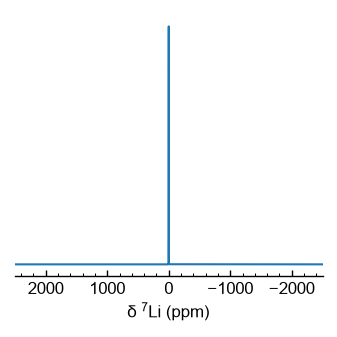

In [16]:
ax = nmr.plot_spectrum_dict(bms_spectrum, axis="ppm", channel="real", normalised=True)
plt.tight_layout()
plt.show()

# Overlay against an experimental spectrum the same way as Section 8.4:
# experimental_dict = nmr.NMR1dimport(r"...")
# ax = nmr.plot_comparison(bms_spectrum, experimental_dict)

### 9.4 Inspect the per-voxel table

`voxel_table` (also returned alongside `bms_spectrum`, and written to CSV
when `save_voxel_table=True`) has one row per evaluation grid point, with
columns `x, y, z, d_iso, delta, eta, N1, N2, N3` -- the position, the
Haeberlen-convention shift parameters, and the three demagnetizing-tensor
eigenvalues at that point.

In [11]:
voxel_table.head()

,x,y,z,d_iso,delta,eta,N1,N2,N3
0,-300.0,-300.0,-300.0000,-0.003284,1.301802,0.085989,-0.000508,0.000240,0.000268
1,-300.0,-300.0,-295.3125,-0.002213,1.325775,0.086122,-0.000517,0.000244,0.000273
2,-300.0,-300.0,-290.6250,-0.001085,1.350211,0.086216,-0.000526,0.000248,0.000277
3,-300.0,-300.0,-285.9375,0.000101,1.375112,0.086270,-0.000535,0.000252,0.000282
4,-300.0,-300.0,-281.2500,0.001348,1.400484,0.086283,-0.000544,0.000257,0.000287


### 9.5 Lower-level: just the per-voxel table, no spectrum

If you only want the demag/shift calculation (e.g. to inspect the field
directly, or assemble several spectra from one simulation without
re-running the FFT step each time -- see 9.8), call `run_bms` directly. It
takes the same particle/box/shape parameters as `generate_bms_spectrum_dict`
minus the nuclide-specific spectrum-assembly ones, and returns just the
DataFrame.

In [12]:
from opennmr.notebook.bms import run_bms, build_box, particles_to_array

df = run_bms(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    box_size=600.0,
    gridpoints=128,
    equation="ellipsoid",
    deformation="A",
    out_dir=None,   # pass a directory to also write BMS_out.csv
    n_jobs=None,
)
df.head()

,x,y,z,d_iso,delta,eta,N1,N2,N3
0,-300.0,-300.0,-300.0000,-0.003284,1.301802,0.085989,-0.000508,0.000240,0.000268
1,-300.0,-300.0,-295.3125,-0.002213,1.325775,0.086122,-0.000517,0.000244,0.000273
2,-300.0,-300.0,-290.6250,-0.001085,1.350211,0.086216,-0.000526,0.000248,0.000277
3,-300.0,-300.0,-285.9375,0.000101,1.375112,0.086270,-0.000535,0.000252,0.000282
4,-300.0,-300.0,-281.2500,0.001348,1.400484,0.086283,-0.000544,0.000257,0.000287


### 9.6 Particles from a raw array, a LAMMPS dump, or a JSON input file

`particles_to_array` normalises a raw `(N,10)`/`(N,11)` array
(`x,y,z,v1,v2,v3,qi,qj,qk,qr`, optionally with a leading id column -- the
same layout a LAMMPS dump uses) into what `run_bms(particles=...)` expects,
as an alternative to building a list of `make_particle()` dicts by hand:

```python
particles_arr = particles_to_array(my_raw_array)  # -> (N,11) array
df = run_bms(particles=particles_arr, magnetic_susceptibility=(...), ...)
```

`build_box(size, gridpoints)` builds just the origin-centred box dict, if
you're assembling an input structure yourself rather than using `run_bms`'s
`box_size=`/`gridpoints=` shortcut.

For the original MATLAB-style workflow -- a `BMS_input*.json` file that
points at a LAMMPS particle-dump file on disk -- use `run` (imported as
`from opennmr.notebook.bms import run`) instead of `run_bms`:

```python
from opennmr.notebook.bms import run
df = run("BMS_input.json", out_dir="./bms_out", n_jobs=None)
```

### 9.7 Performance: `n_jobs`

Each particle's demagnetizing-field/shift calculation is independent of
every other particle, so `run`/`run_bms` parallelise the per-particle loop
across a process pool. `n_jobs=None` (the default) uses `os.cpu_count()`;
pass `n_jobs=1` to run serially in a single process, which is useful when
debugging or for very small particle counts where pool startup overhead
isn't worth it.

### 9.8 Advanced building blocks

These live in `opennmr.notebook.bms.<module>` and are what
`generate_bms_spectrum_dict`/`run_bms` are built from -- reach for them
directly only if you need to deviate from the standard pipeline:

- **`bms.spectrum.assemble_spectrum(df, spin_rate_hz, BF1, SFO1, nuclide, path, ...)`**
  -- turns a per-voxel table (from `run`/`run_bms`) into a `spectrum_dict`.
  Call this directly if you already have `BF1`/`SFO1` from elsewhere, or
  want to re-broaden/re-assemble the *same* voxel table (different
  `spin_rate_hz`, `linewidth_hz`, `sw_ppm`, ...) without re-running the
  demag/shift calculation.
- **`bms.mas_sidebands.sideband_manifold(delta, eta, spin_rate, iso=0.0, ...)`**
  -- computes the powder-averaged MAS spinning-sideband manifold (orders and
  relative intensities) for a single CSA-like `(delta, eta)` site, given a
  spin rate. Useful for checking a sideband pattern in isolation, without
  running a full particle simulation.
- **`bms.geometry.shape_function(sim_part, x, y, z)`** (and
  `ellipsoid_mask`/`hexagonal_mask`/`donut_mask`) -- the particle mask
  functions used internally; handy for plotting/checking a particle's shape
  directly (e.g. slicing it with matplotlib) before running the full
  simulation.

`verify_rotation_convention.py` (a standalone script, not a notebook
function -- run it from a terminal, not imported here) is worth running
once against your own particle-orientation data: it checks that the
quaternion rotation convention used by `geometry.py` matches what your
particle generator actually produces, using a tilted needle-shaped test
particle with a known expected orientation.

### 9.9 Visualizing particle shapes (`geometry.py`)

`shape_function(sim_part, x, y, z)` dispatches on `sim_part["Equation"]` to
`ellipsoid_mask`, `hexagonal_mask`, or `donut_mask` -- each returns a smooth
`0..1` occupancy value (`1` = fully inside the particle). Calling the mask
functions directly instead of through `shape_function` is identical --
`shape_function` is just the `Equation`-based dispatcher.

Note that `sim_part` here is one of the richer per-particle dicts built
internally by `inp_part` (or, for a one-off demo like below, hand-built) --
it carries the shape-function parameters (`r`, `t`, `sl`, `thresh`)
alongside the geometry (`v1, v2, v3`, `q`, `Deformation`), unlike the plain
dict `make_particle` returns. `quat_to_rotmat(q)` is the shared
quaternion-to-rotation-matrix helper all three mask functions use
internally -- see the orientation-convention caveats in `geometry.py`'s
module docstring and 9.14 below before trusting orientation-sensitive
results.

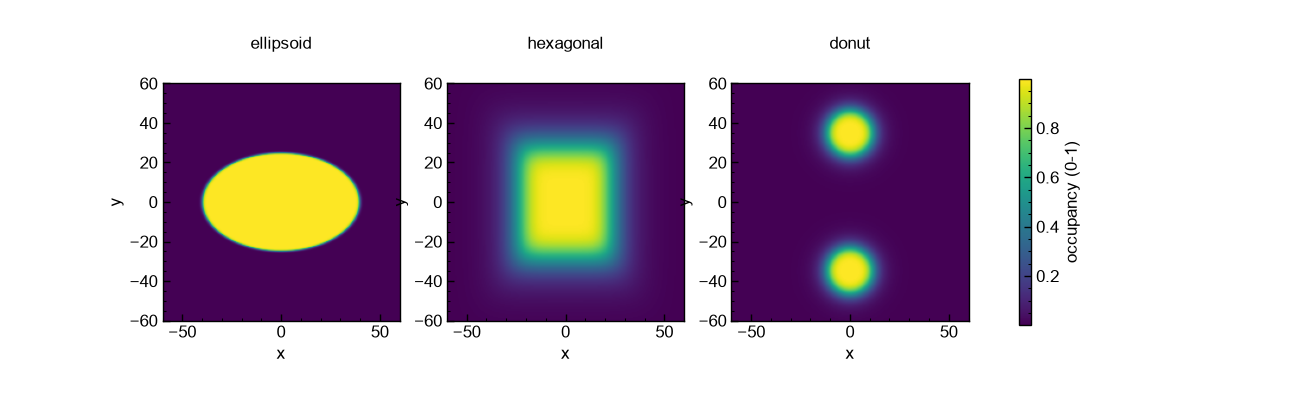

shape_function == ellipsoid_mask directly: True


array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00, -2.22044605e-16,  1.00000000e+00],
       [ 0.00000000e+00, -1.00000000e+00, -2.22044605e-16]])

In [17]:
from opennmr.notebook.bms.geometry import (
    shape_function, ellipsoid_mask, hexagonal_mask, donut_mask, quat_to_rotmat,
)

def make_sim_part(equation, deformation, v1, v2, v3, q=(1, 0, 0, 0),
                   r=2, t=2, sl=50, thresh=0.99, posc=(0.0, 0.0, 0.0)):
    """A minimal stand-in for what `inp_part` builds, for demo purposes below."""
    return {
        "Equation": equation, "Deformation": deformation,
        "v1": v1, "v2": v2, "v3": v3,
        "q": np.array(q, dtype=float),
        "r": r, "t": t, "sl": sl, "thresh": thresh,
        "posc": np.array(posc, dtype=float),   # needed by simulate.evaluate, 9.12
        "vol": (4.0 / 3.0) * np.pi * v1 * v2 * v3,  # needed by evaluate's far-field fallback
    }

# a 2-d grid through z=0 to visualize each shape's cross-section
lin = np.linspace(-60, 60, 200)
X_, Y_ = np.meshgrid(lin, lin, indexing="ij")
Z_ = np.zeros_like(X_)

shapes = {
    "ellipsoid": make_sim_part("ellipsoid", "A", v1=40, v2=25, v3=25),
    "hexagonal": make_sim_part("hexagonal", "A", v1=30, v2=0, v3=50, sl=6),  # sl reused as hex exponent p
    "donut":     make_sim_part("donut",     "A", v1=35, v2=12, v3=0, sl=6), # sl reused as donut exponent p
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, sp) in zip(axes, shapes.items()):
    c0 = shape_function(sp, X_, Y_, Z_)
    im = ax.imshow(c0.T, origin="lower", extent=[lin[0], lin[-1], lin[0], lin[-1]])
    ax.set_title(name)
    ax.set_xlabel("x"); ax.set_ylabel("y")
fig.colorbar(im, ax=axes, shrink=0.8, label="occupancy (0-1)")
plt.show()

# shape_function is just the Equation-based dispatcher:
sp = shapes["ellipsoid"]
print("shape_function == ellipsoid_mask directly:",
      np.allclose(shape_function(sp, X_, Y_, Z_), ellipsoid_mask(sp, X_, Y_, Z_)))

# quat_to_rotmat on its own -- e.g. to check what rotation a given
# make_particle(..., quaternion=...) actually applies:
quat_to_rotmat([0.707, 0.707, 0, 0])  # ~90 deg about x, (qw,qx,qy,qz)

### 9.10 Visualizing the demagnetizing field for one particle (`demag.py`)

`build_kspace_kernel(sim_str)` builds the box's real-space/k-space grids
once -- this is the expensive part that `run`/`run_bms` build once per
worker process and reuse across particles (9.7). `demag_calc(sim_str,
sim_part, kernel=...)` then computes the raw (no `-1/3` correction)
demagnetizing tensor field for one particle on that grid via the
FFT/dipolar-kernel trick, returning a `(nx, ny, nz, 3, 3)` array. Passing
`kernel=None` (the default) rebuilds it automatically -- convenient for a
single one-off particle like below, but wasteful in a loop over many
particles on the same box.

kernel components: ['KX', 'KY', 'KZ', 'X', 'Y', 'Z', 'knsq', 'xvec', 'yvec', 'zvec']
demag_tensor shape: (32, 32, 32, 3, 3)


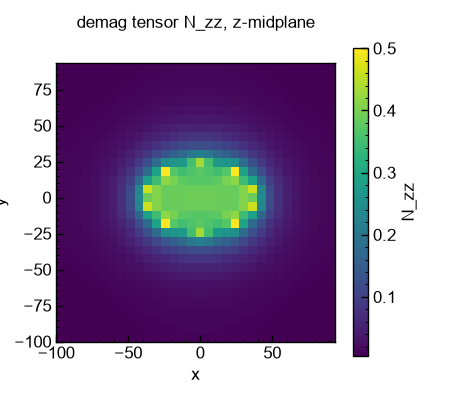

In [18]:
from opennmr.notebook.bms import build_box  # (already imported in 9.5, shown again here for clarity)
from opennmr.notebook.bms.io_utils import inp_sim
from opennmr.notebook.bms.demag import build_kspace_kernel, demag_calc

sim_str_demo = inp_sim(build_box(200, gridpoints=32))
kernel = build_kspace_kernel(sim_str_demo)
print("kernel components:", sorted(kernel.keys()))

sim_part_demo = make_sim_part("ellipsoid", "A", v1=40, v2=25, v3=25)
demag_tensor, (xvec, yvec, zvec) = demag_calc(sim_str_demo, sim_part_demo, kernel=kernel)
print("demag_tensor shape:", demag_tensor.shape)  # (nx, ny, nz, 3, 3)

# slice through the mid-plane (grid index nearest z=0)
zi = np.argmin(np.abs(zvec))
plt.figure(figsize=(4.5, 4))
plt.imshow(demag_tensor[:, :, zi, 2, 2].T, origin="lower",
           extent=[xvec[0], xvec[-1], yvec[0], yvec[-1]])
plt.colorbar(label="N_zz")
plt.title("demag tensor N_zz, z-midplane")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

### 9.11 Shift tensors for one particle (`shift.py`)

- `point_dipole(x, y, z)` -- the vectorized far-field point-dipole formula,
  used by `simulate.evaluate` (9.12) for evaluation points that fall
  outside the FFT grid.
- `shielding_bms(sim_part, demag_tensor)` -- multiplies by the particle's
  susceptibility tensor and applies the `-1/3` Lorentz-sphere correction
  wherever `trace(demag_tensor) > sim_part["thresh"]` (i.e. "inside" the
  particle core). Needs `sim_part["Chi_tensor"]` and `sim_part["thresh"]`
  -- both are set by `inp_part`, not by plain `make_particle`, so they're
  added by hand below for this one-off demo particle.
- `tensor2haeberlen(tensor)` -- eigendecomposes a `(..., 3, 3)` symmetric
  tensor field into `[iso, delta, eta]` (Haeberlen convention).

point_dipole shape: (3, 3, 3)
shift_tensor: (32, 32, 32, 3, 3)  haeb: (32, 32, 32, 3)


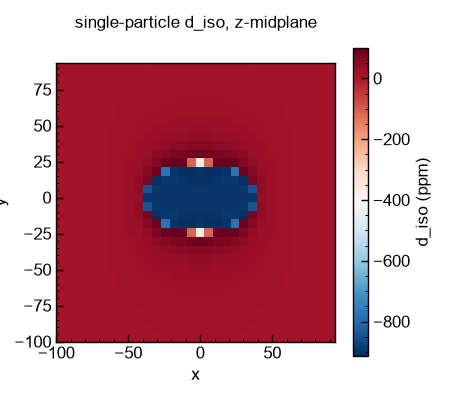

In [19]:
from opennmr.notebook.bms.shift import point_dipole, shielding_bms, tensor2haeberlen

# point_dipole is fully vectorized over array inputs
xs = np.array([100.0, 150.0, 200.0]); ys = np.zeros(3); zs = np.zeros(3)
T_dip = point_dipole(xs, ys, zs)
print("point_dipole shape:", T_dip.shape)  # (3, 3, 3)

sim_part_demo["Chi_tensor"] = np.diag([2.87e-3, 3.13e-3, 2.27e-3])
sim_part_demo["thresh"] = 0.99

shift_tensor = shielding_bms(sim_part_demo, demag_tensor)
haeb = tensor2haeberlen(shift_tensor)          # (..., [iso, delta, eta])
print("shift_tensor:", shift_tensor.shape, " haeb:", haeb.shape)

# visualize this one particle's own d_iso (haeb[...,0]) on the z-midplane
plt.figure(figsize=(4.5, 4))
plt.imshow(haeb[:, :, zi, 0].T, origin="lower", cmap="RdBu_r",
           extent=[xvec[0], xvec[-1], yvec[0], yvec[-1]])
plt.colorbar(label="d_iso (ppm)")
plt.title("single-particle d_iso, z-midplane")
plt.xlabel("x"); plt.ylabel("y")
plt.show()

### 9.12 Low-level `simulate.evaluate`

This is what `run`/`run_bms` call once per particle: it takes the
`(nx, ny, nz, 3, 3)` demag tensor field from `demag_calc` and interpolates
it onto arbitrary evaluation points (`sim_str["evalpoints"]`, built by
`inp_sim`), falling back to `point_dipole` for points outside the FFT
grid. `compute_haeberlen=True` additionally returns that one particle's
own Haeberlen decomposition (off by default -- `run()` only needs it for
the *summed* tensor across all particles, not each one individually).

In [20]:
from opennmr.notebook.bms.simulate import evaluate

result = evaluate(sim_str_demo, sim_part_demo, demag_tensor, (xvec, yvec, zvec),
                   compute_haeberlen=True)
print(sorted(result.keys()))
print("demag_tensor:", result["demag_tensor"].shape)
print("shift_tensor:", result["shift_tensor"].shape)
print("haeb_shift_tensor:", result["haeb_shift_tensor"].shape)

['demag_tensor', 'haeb_shift_tensor', 'pos', 'shift_tensor']
demag_tensor: (35937, 3, 3)
shift_tensor: (35937, 3, 3)
haeb_shift_tensor: (35937, 3)


### 9.13 Visualizing MAS sideband manifolds (`mas_sidebands.py`)

`haeberlen_to_principal(iso, delta, eta)` converts a Haeberlen-convention
`(iso, delta, eta)` triple back to principal-axis values `(sxx, syy, szz)`.
`sideband_manifold(delta, eta, spin_rate, iso=0.0, ...)` computes the
powder-averaged MAS spinning-sideband intensities for a single CSA-like
site by direct numerical simulation -- returns `(orders, intensities)`
with `orders` the integer sideband index (`0` = centerband) and
`intensities` normalized to sum to 1. This is the same manifold
calculation `assemble_spectrum` (9.2) runs per voxel internally; useful
on its own to check a sideband pattern in isolation.

Units: `delta`/`eta`/`iso`/`spin_rate` must all be in the same units
(e.g. ppm, with the MAS rate converted from Hz via `spin_rate_Hz /
BF1_MHz`).

principal values: sxx=-26.00, syy=-14.00, szz=40.00
Parseval check (sideband intensities should sum to ~1.0): 1.0


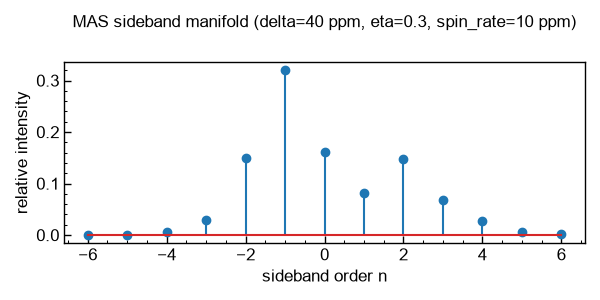

delta=0 (no anisotropy): [0] [1.]
very fast spinning, centerband fraction: 0.999754943969225


In [22]:
from opennmr.notebook.bms.mas_sidebands import sideband_manifold, haeberlen_to_principal

sxx, syy, szz = haeberlen_to_principal(iso=0.0, delta=40.0, eta=0.3)
print(f"principal values: sxx={sxx:.2f}, syy={syy:.2f}, szz={szz:.2f}")

orders, intens = sideband_manifold(delta=40.0, eta=0.3, spin_rate=10.0, max_order=6)
print("Parseval check (sideband intensities should sum to ~1.0):", intens.sum())

plt.figure(figsize=(6, 3))
plt.stem(orders, intens)
plt.xlabel("sideband order n"); plt.ylabel("relative intensity")
plt.title("MAS sideband manifold (delta=40 ppm, eta=0.3, spin_rate=10 ppm)")
plt.tight_layout()
plt.show()

# sanity cases: delta=0 -> single centerband; very fast spinning -> centerband-dominated
o0, i0 = sideband_manifold(delta=0.0, eta=0.0, spin_rate=10.0)
print("delta=0 (no anisotropy):", o0, i0)

o_fast, i_fast = sideband_manifold(delta=40.0, eta=0.3, spin_rate=1000.0, max_order=3)
print("very fast spinning, centerband fraction:", i_fast[o_fast == 0][0])

### 9.14 Rotation-convention self-check

`bms/verify_rotation_convention.py` is a standalone script (not a plain
importable function) that cross-checks `geometry.quat_to_rotmat` +
`_to_local_frame` against an independently-written textbook
quaternion-to-rotation-matrix, confirming the *algebraic* identity
documented in `geometry.py`'s module docstring. It does **not** tell you
whether that net convention matches what your particle dump intends
(body->world vs world->body) -- that depends on your upstream data
generation, and needs the manual visual check its own
`part2_orientation_sanity_check_template()` prints instructions for.

Worth running once after any change to `geometry.py`, or before trusting
orientation-sensitive results for the first time on a new dataset.

In [25]:
import runpy, os
import opennmr.notebook.bms as _bms_pkg

runpy.run_path(
    os.path.join(r"C:\Users\quark\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\opennmr\notebook\scripts\verify_rotation_convention.py"),
    run_name="__main__",
)

Part 1: checking pts @ quat_to_rotmat(q) == R_std(q) @ pt ...
  max abs error over 200 random quaternions/points: 4.441e-16
  PASS: current code's net effect is pts@R == R_std(q) @ pt, as documented.

Part 2: orientation sanity-check template (needs your judgement)
----------------------------------------------------------------------
  mask value 15 units out along world x-axis: 0.0000  (outside -> not the long axis)
  mask value 15 units out along world y-axis: 1.0000  (inside/near particle -> long axis is here)
  mask value 15 units out along world z-axis: 0.0000  (outside -> not the long axis)

  A 90 deg rotation about world x should swap which of world y/z
  the long (v3) axis points along, leaving world x unaffected.
  Confirm the printed pattern matches what YOUR quaternion
  convention (body->world vs world->body, as produced by your
  particle generator) predicts -- this script does not know that
  convention for you.


{'__name__': '__main__',
 '__doc__': '\nStandalone check of what geometry.quat_to_rotmat + geometry._to_local_frame\nactually compute, and a template for validating the orientation convention\nagainst a known case.\n\nPart 1 (always run, no ground truth needed): confirms the algebraic identity\ndescribed in geometry.py\'s module docstring --\n\n    pts @ quat_to_rotmat(q)  ==  R_std(q) @ pt   for every point pt\n\nwhere R_std(q) is the textbook (non-conjugated) quaternion-to-rotation-matrix,\nbuilt independently here so it isn\'t just checking the code against itself.\n\nPart 2 (a template, not a finished test): shows how to sanity-check the\nconvention against a case you *can* reason about by eye -- a long, thin\nellipsoid rotated by a known angle about a known axis. Fill in the\n"expected" direction for your own dump\'s quaternion convention (body->world\nor world->body) and confirm the mask agrees. This script cannot tell you\nwhich convention your particle dump actually uses -- onl

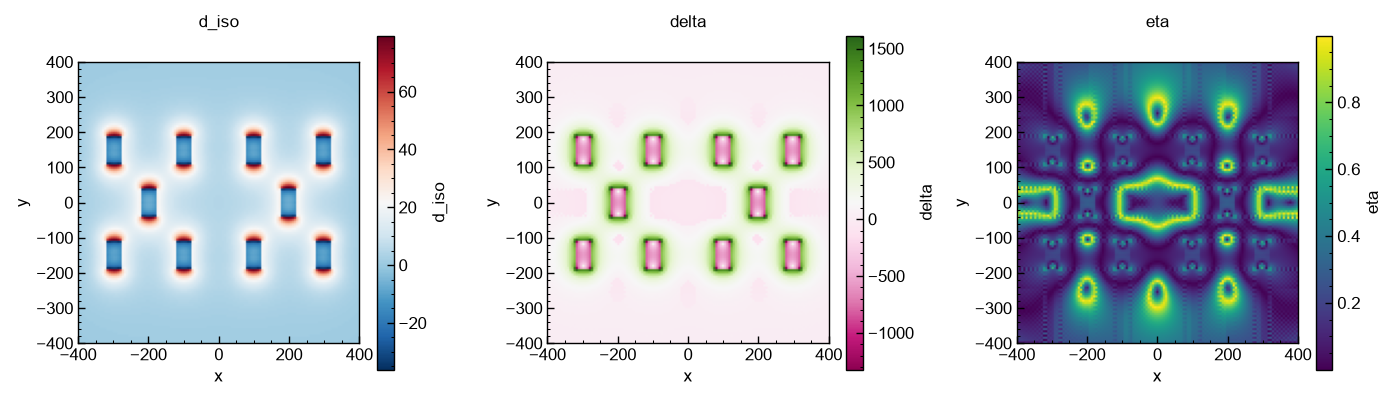

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from opennmr.notebook.bms import run_bms

particles_10 = [
    nmr.make_particle(x=x, y=y, z=0, size=(40, 40, 40))
    for x, y in [(-300,-150),(-100,-150),(100,-150),(300,-150),(-300,150),
                 (-100,150),(100,150),(300,150),(-200,0),(200,0)]
]

df10 = run_bms(
    particles_10,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    box_size=800.0,     # must comfortably enclose all 10 particle positions/sizes
    gridpoints=128,
    equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)
    n_jobs=None,
)

# plot d_iso, delta, eta side by side on the z-midplane
zmid = df10["z"].unique()[np.argmin(np.abs(df10["z"].unique()))]
mid = df10[np.isclose(df10["z"], zmid)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, cmap in zip(axes, ["d_iso", "delta", "eta"], ["RdBu_r", "PiYG", "viridis"]):
    pivot = mid.pivot(index="y", columns="x", values=col)
    im = ax.imshow(pivot.values, origin="lower", cmap=cmap,
                    extent=[pivot.columns.min(), pivot.columns.max(),
                            pivot.index.min(), pivot.index.max()])
    fig.colorbar(im, ax=ax, label=col)
    ax.set_title(col); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

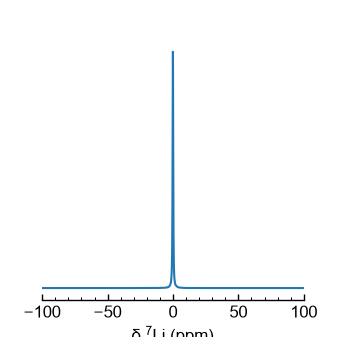

In [ ]:
particles_20 = [
    nmr.make_particle(x=x, y=y, z=z, size=(32, 30, 42))
    for x, y, z in [(-300,-150, 5),(-100,-150, 5),(100,-150, 5),(300,-150, 5),(-300,150, 5),
                    (-100,150, 5),(100,150, 5),(300,150, 5),(-200,0, 5),(200,0, 5),
                    (60, 0, 5), (60, 0, -5), (-60, 0, 5), (-60, 0, -5), (0, 60, 5),
                    (0, -60, 5), (0, 0, 5), (0, 0, -5), (0, 0, 0)]   # however you're generating/loading them
]

local_shift_contribution = [[-850,    -126,   -80.42],
                            [-126.47,  529.61,  39.46],
                            [-80.42,    39.46, 368.39]]

rotor_contribution = [[327.5, 0, 0],
                      [0, 327.5, 0],
                      [0, 0, -655.0]]

bms_spectrum, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles_20,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    nuclide="7Li",
    B0_tesla=9.4,                  # 400 MHz spectrometer
    spin_rate_hz=30000,           # MAS rate -> sideband spacing on the ppm axis

    box_size=1200.0,              # enclose all 20 particles
    gridpoints=32,                # FFT grid resolution per axis
    equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)

    local_shift_contribution=local_shift_contribution,
    rotor_contribution=rotor_contribution,

    linewidth_hz=50.0,
    n_points=32768,
    sw_ppm=2000.0,
    max_order=8,                  # highest sideband order kept
    n_jobs=None,                  # parallelize over the 20 particles
)

ax = nmr.plot_spectrum_dict(bms_spectrum, axis="ppm", channel="real", normalised=True, xlims=[-100, 100])
plt.tight_layout()
plt.show()

sample_particle_sizes: nominal vs realised (post-truncation), per axis (v1,v2,v3):
  mean requested : [30. 33. 42.]
  mean realised  : [30.0763157  32.5574845  42.05100996]
  spread requested (meaning depends on kind='gaussian'): [ 5.  5. 10.]
  std realised   : [4.80589434 5.12642779 9.99652734]
random_close_pack: placed 200/200 particles (100.0%), achieved volume fraction = 0.040


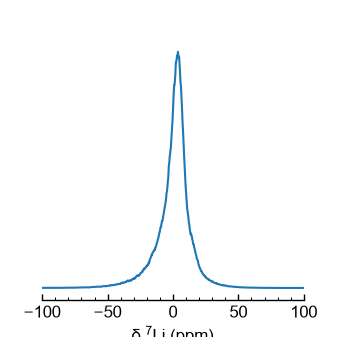

In [ ]:
from opennmr.notebook.bms.packing import random_close_pack

particles, stats = random_close_pack(
    n=200, box_size=800.0,
    mean_size=(30, 33, 42), spread_size=(5, 5, 10),
    size_dist="gaussian", equation="hexagonal", seed=0,
)

local_shift_contribution = [[-850,    -126,   -80.42],
                            [-126.47,  529.61,  39.46],
                            [-80.42,    39.46, 368.39]]

rotor_contribution = [[327.5, 0, 0],
                      [0, 327.5, 0],
                      [0, 0, -655.0]]

spectrum_dict, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    nuclide="7Li",
    B0_tesla=9.4,                  # 400 MHz spectrometer
    spin_rate_hz=30000,           # MAS rate -> sideband spacing on the ppm axis

    gridpoints=64,                # FFT grid resolution per axis
    #equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    #deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)

    local_shift_contribution=local_shift_contribution,
    rotor_contribution=rotor_contribution,

    linewidth_hz=50.0,
    n_points=32768,
    sw_ppm=2000.0,
    max_order=8,                  # highest sideband order kept
    n_jobs=None,
)

ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True, xlims=[-100, 100])
plt.tight_layout()
plt.show()

In [7]:
from opennmr.notebook.bms.packing import grow_and_separate_pack

particles, stats = grow_and_separate_pack(
    n=200, box_size=120.0,
    mean_size=(30, 33, 42), spread_size=(5, 5, 10),
    size_dist="gaussian", equation="hexagonal", seed=0,
    relax_iters_per_step=100, 
)
# stats['achieved_volume_fraction'], stats['n_at_full_size'], stats['mean_achieved_size_fraction']

local_shift_contribution = [[-850,    -126,   -80.42],
                            [-126.47,  529.61,  39.46],
                            [-80.42,    39.46, 368.39]]

rotor_contribution = [[327.5, 0, 0],
                      [0, 327.5, 0],
                      [0, 0, -655.0]]

spectrum_dict, voxel_table = nmr.generate_bms_spectrum_dict(
    particles=particles,
    magnetic_susceptibility=(2.87e-3, 3.13e-3, 2.27e-3),
    nuclide="7Li",
    B0_tesla=9.4,                  # 400 MHz spectrometer
    spin_rate_hz=30000,           # MAS rate -> sideband spacing on the ppm axis

    gridpoints=128,                # FFT grid resolution per axis
    equation="hexagonal",         # "ellipsoid" | "hexagonal" | "donut"
    deformation="A",               # only used by "hexagonal"/"donut" -- which world axis is the long axis
    r=10, t=10,                     # shape-function exponents. (2,2) is ellipsoid; (10,10) is cuboid; (2,8) is a cylinder
    slope_filter=2000,              # steepness of the particle edge (higher = sharper boundary)

    local_shift_contribution=local_shift_contribution,
    rotor_contribution=rotor_contribution,

    linewidth_hz=50.0,
    n_points=32768,
    sw_ppm=2000.0,
    max_order=8,                  # highest sideband order kept
    n_jobs=None,
)

ax = nmr.plot_spectrum_dict(spectrum_dict, axis="ppm", channel="real", normalised=True, xlims=[-1000, 1000], 
                            pl_width=8.0, pl_height=4.0)
plt.tight_layout()
plt.show()

sample_particle_sizes: nominal vs realised (post-truncation), per axis (v1,v2,v3):
  mean requested : [30. 33. 42.]
  mean realised  : [30.0763157  32.5574845  42.05100996]
  spread requested (meaning depends on kind='gaussian'): [ 5.  5. 10.]
  std realised   : [4.80589434 5.12642779 9.99652734]
grow_and_separate_pack: placed 200/200 particles (100.0%), 0/200 at full nominal size, mean achieved size fraction = 0.279, achieved volume fraction = 0.258
  Some particles were shrunk (isotropically, aspect ratio preserved) to fit -- check achieved_size_fraction per-particle (`s` in the source) if the size distribution fidelity matters for your analysis, or lower n / mean_size / packing density expectations.


OSError: [WinError 1450] Insufficient system resources exist to complete the requested service

## 10. Fitting pNMR Spectra Against CIF-Predicted Environments

Section 8 *simulates* a spectrum from a CIF: it enumerates every
disordered local environment, works out its shift from `shift_dict`, and
broadens the result into a lineshape. This section goes the other
direction -- it *fits* an experimental spectrum, using the CIF prediction
to decide where the peaks should be, so that a peak's centre comes from
the structure rather than from a guess. Only width, intensity, and (for
pseudo-Voigt) the Gaussian/Lorentzian mixing fraction are fitted by
default; the shift is fixed at its CIF-predicted value unless you
explicitly ask for it to float.

The building blocks, used in this order:

1. **`predict_environments`** -- enumerate every (site, disorder-config)
   shift the CIF predicts, unbroadened.
2. **`group_environments`** -- merge shifts too close together to resolve
   into single candidate peaks, remembering which environments went into
   each one.
3. **`fit_predicted_spectrum`** -- filter those groups against your data
   (region of interest, signal-to-noise) and fit one peak per surviving
   group -- the *maximal* fit, one peak per CIF environment group.
4. **`merge_low_integral_peaks` / `merge_groups_to_picks`** -- simplify a
   crowded maximal fit into far fewer peaks, automatically or by hand.
5. **`refit_merged_groups`** -- re-fit the simplified peak set, this time
   with each centre free to move.
6. **`fit_cif_envelope`** -- a different strategy entirely: fit the whole
   predicted shift distribution as one continuous envelope, for CIFs
   whose disorder is too combinatorially rich to resolve into discrete
   peaks at all.

All of it lives in `pnmr_fit`, imported below as `pf`.

In [ ]:
import numpy as np
import pandas as pd
from pymatgen.core import Structure, Lattice

from opennmr.notebook import pnmr_fit as pf

pd.set_option("display.width", 140)
np.random.seed(0)


### 10.1 `predict_environments` -- enumerate every disordered environment

The same underlying calculation as Section 8's `generate_spectrum_dict` /
`build_shift_table` -- read the CIF's site occupancies, find neighbours
by shell, enumerate every disorder configuration, and total up the shift
from `shift_dict` -- but returned as a flat, **unbroadened** table (no
spectrum built here) with two extra columns:

- `label` -- compact string, nonzero counts only, e.g. `"NN:5Fe+1Mn NNN:6Fe"`
- `composition` -- a dict `{shell: {species: count, ...}, ...}` listing
  *every* species in `shift_dict[shell]`, including zeros -- used later
  for the full per-peak breakdown (Section 10.10)

For this section we'll build a small toy CIF to work with first --
a rocksalt-like lattice with a Li site and a Fe/Mn-disordered metal site
(70:30), a stand-in for something like the mixed-metal site in an
LFP-type material -- so the whole workflow is reproducible without
needing your own CIF/spectrum yet. A worked example on real data follows
in 10.12-10.13.

In [ ]:
# ---------------------------------------------------------------------------
# Toy CIF: rocksalt-like lattice, Li site + Fe/Mn-disordered metal site
# ---------------------------------------------------------------------------
lattice = Lattice.cubic(4.0)
struct = Structure(lattice, ["Li", "Fe", "O"], [[0, 0, 0], [0.5, 0.5, 0.5], [0.5, 0, 0]])
struct.replace(1, {"Fe": 0.7, "Mn": 0.3})
struct.make_supercell([2, 2, 2])
struct.to(filename="toy.cif")

shell_bins = [("NN", 0.0, 3.7), ("NNN", 3.7, 4.2)]
shift_dict = {
    "NN": {"Fe": 150.0, "Mn": 400.0},   # ppm per NN Fe / Mn
    "NNN": {"Fe": 8.0, "Mn": 20.0},     # ppm per NNN Fe / Mn (Li has no shift
                                        # entry, so it contributes 0 -- see
                                        # the printed warning when this runs)
}

predicted = pf.predict_environments("toy.cif", "Li", shell_bins, shift_dict,
                                     ignore_species=["O"])
predicted.sort_values("Total_shift")[["Site", "Config", "Total_shift", "p", "label"]].head(10)


### 10.2 `group_environments` -- merging shifts you can't resolve

`tolerance` (ppm) sets how close two predicted shifts have to be before
they're treated as one peak. Left unset, it defaults to the *smallest
non-zero pathway contribution* in `shift_dict` -- a reasonable starting
guess, but not a substitute for thinking about your actual experimental
resolution (10.13 works through a real case where this default goes
badly wrong).

`method` controls how grouping is done:

- **`'probability'`** (default) -- seed-based: take the single most
  probable environment remaining, pull in everything within
  `+/- 0.5*tolerance` of *its* shift, remove them from the pool, repeat.
  Each group is anchored to one seed, so its span can never exceed
  `tolerance` -- it can't chain.
- **`'sequential'` / `'hierarchical'`** -- decide grouping pairwise along
  the sorted shift axis (single-linkage clustering) instead, and so
  *can* chain: if A-B and B-C are each within tolerance but A-C isn't,
  all three still end up in one group, however far apart A and C are.
  `max_group_span` (raises an error if any group exceeds it) is a useful
  guard if you use either of these.

The result's `members` column records exactly which environments went
into each group, and each member's `fraction_in_group` -- its CIF
probability as a fraction of the group total -- is what later splits a
fitted peak's integral back out per environment (10.5).

In [ ]:
groups, tolerance = pf.group_environments(predicted, shift_dict=shift_dict)
print(f"Tolerance used for grouping: {tolerance} ppm "
      f"(= smallest non-zero pathway contribution, NNN-Fe)")
groups[["group_shift", "group_p", "n_members"]]


### 10.3 (Toy example only) Building a synthetic spectrum to fit

In real use you'd load your own experimental spectrum with
`nmr.NMR1dimport` (Section 1) and pass that `results` dict straight to
`fit_predicted_spectrum` below. Here we fabricate one from a subset of
the predicted groups, plus Gaussian broadening and noise, purely so the
rest of this section has something concrete to fit.

In [ ]:
x_ppm = np.linspace(3400, 1000, 4000)  # nmrtools stores ppm axes descending
fwhm_true = 12.0
sigma_true = fwhm_true / (2 * np.sqrt(2 * np.log(2)))

true_peaks = groups[groups["group_p"] > 0.01]  # pretend the rare, high-Mn tail was never measured
y = np.zeros_like(x_ppm)
for _, row in true_peaks.iterrows():
    y += 50 * row["group_p"] * np.exp(-0.5 * ((x_ppm - row["group_shift"]) / sigma_true) ** 2)
y += np.random.normal(0, 0.03, size=y.shape)

results = {
    "x_ppm": x_ppm, "x_Hz": x_ppm * 155.5,
    "real_spectrum": y, "normalised_real_spectrum": y / np.max(np.abs(y)),
    "imag_spectrum": np.zeros_like(y), "normalised_imag_spectrum": np.zeros_like(y),
    "nuclide": "7Li", "BF1": 155.5, "SFO1": 155.5, "path": "synthetic",
}


### 10.4 `fit_predicted_spectrum` -- the maximal fit

The end-to-end driver: predicts, groups, then internally

- **`select_groups`** -- drops groups outside `fit_regions` (default:
  the whole spectrum) and groups whose local signal-to-noise in the
  *experimental* data falls below `snr_threshold` -- a CIF-predicted
  site isn't necessarily an observable one.
- **`groups_to_peak_defs`** -- one peak per surviving group, shift FIXED
  at the CIF-predicted value (`float_shift_window` relaxes this).
- **`fitting.fit_spectrum`** -- the actual nonlinear fit.

giving one fitted peak per surviving CIF-environment group -- the
*maximal* fit, before any simplification. Key arguments: `fit_regions`,
`tolerance`/`group_method`/`max_group_span` (grouping, 10.2),
`snr_threshold` (filtering), `peak_type`/`fwhm_init`/`fwhm_bounds`
(the lineshape), `float_shift_window` (let shift move instead of fixing
it). `show_report=True` prints a fit-quality report, bound-hit warnings,
and the environment report (10.5) automatically.

In [ ]:
out = pf.fit_predicted_spectrum(
    results, "toy.cif", "Li", shell_bins, shift_dict,
    ignore_species=["O"],
    fit_regions=[(1100, 2600)],   # excludes the high-Mn tail -- also
                                   # exercises the "outside fit_regions"
                                   # rejection path, on top of those
                                   # groups being genuinely absent here
    snr_threshold=3.0,
    peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
    use_normalised=False,
    show_plot=True, show_report=True,
)


### 10.5 Reading the output

`out` is a dict; the pieces worth knowing:

- **`kept` / `dropped`** -- which predicted groups survived filtering,
  and (for `dropped`) why: `"outside fit_regions"` or
  `"below S/N threshold"`.
- **`integrals` / `integrals_norm` / `integral_errors`** -- one entry per
  *fitted peak* (i.e. per group).
- **`environment_report`** -- `split_integrals_by_environment`'s output:
  each fitted peak's integral divided back out across its member
  environments, in proportion to their CIF-probability ratio *within*
  that group -- one row per individual environment, not per peak.

Both `print_environment_report` (called automatically above via
`show_report=True`) and this DataFrame are worth checking against
whatever ground truth you have.

In [ ]:
true_frac = true_peaks.set_index("group_shift")["group_p"]
true_frac = true_frac / true_frac.sum()

print("Recovered vs. true peak fraction (integral_pct_of_total, summed per peak):")
recovered = out["environment_report"].groupby("peak_shift")["integral_pct_of_total"].sum()
for shift, true_pct in (100 * true_frac).items():
    print(f"  {shift:8.1f} ppm   true {true_pct:6.2f}%   "
          f"recovered {recovered.get(shift, float('nan')):6.2f}%")

print(f"\n{len(out['kept'])} peaks kept, {len(out['dropped'])} groups dropped "
      f"(see out['dropped'] for why).")
out["environment_report"].head()


### 10.6 Driving the lower-level pieces yourself

As in Section 3, if you want more control -- fitting several regions
differently, or reusing a `groups` table across several experimental
spectra -- `fit_predicted_spectrum`'s three internal steps are ordinary
functions:

In [ ]:
kept, dropped, noise = pf.select_groups(
    groups, results, fit_regions=[(1100, 2600)], snr_threshold=3.0, tolerance=tolerance,
)
peak_defs = pf.groups_to_peak_defs(
    kept, peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
)
print(f"{len(kept)} kept, {len(dropped)} dropped, noise estimate = {noise:.4g}")
peak_defs[0]


### 10.7 Simplifying a crowded fit automatically: `merge_low_integral_peaks`

A CIF with a lot of combinatorial disorder can produce far more
CIF-resolvable groups than your spectrum can actually resolve. Rather
than hand-picking which to combine, `merge_low_integral_peaks` absorbs
low-integral peaks into their nearest neighbour automatically. A peak is
a merge candidate if its integral is below `integral_threshold`, below
`relative_threshold` (default 5%) of the biggest peak, or (if
`integral_errors` is given) statistically indistinguishable from zero at
`n_sigma`. Merging cascades -- a merged peak can itself absorb further
neighbours -- and is greedy/order-dependent, so inspect the returned
`merge_log` before trusting it, the same way you'd check `kept`/`dropped`
above.

`relative_threshold` is lowered to 20% below purely so this small toy
example (whose peaks are all fairly evenly sized) actually produces a
merge to look at -- the 5% default is more appropriate once you have a
genuinely crowded fit, as in the real-data example in 10.13.

In [ ]:
merged_groups, merge_log = pf.merge_low_integral_peaks(
    out["kept"], out["integrals"],
    integral_errors=out["integral_errors"],
    relative_threshold=0.2,
    merge_tolerance=300.0,   # ppm -- how close two peaks must be to merge
)
print(merge_log)         # exactly what got absorbed into what
merged_groups[["group_shift", "group_p", "n_source_peaks", "source_span"]]


### 10.8 Simplifying a fit manually: `merge_groups_to_picks`

If you'd rather choose the final peak centres yourself -- read off the
maximal fit or the raw spectrum by eye -- `merge_groups_to_picks` merges
every maximal-fit peak onto whichever `pick` is nearest to it, no
threshold involved. `assignment_report` shows which peak went to which
pick and how far; a `pick_shift` far from the resulting `group_shift`
(the CIF-probability-weighted prediction for what actually got assigned
to it) is a sign you picked a point the CIF prediction doesn't support.

In [ ]:
picks_groups, assignment_report = pf.merge_groups_to_picks(
    out["kept"], picks=[1350.0, 2000.0], integrals=out["integrals"],
)
print(assignment_report)
picks_groups[["pick_shift", "group_shift", "n_source_peaks"]]


### 10.9 Refitting a simplified peak set: `refit_merged_groups`

Re-fits a simplified peak set (from either 10.7 or 10.8) against the
same spectrum, this time with each centre free to move within
`+/- shift_float_window` ppm -- safer now than on the maximal fit, since
there are far fewer, better-separated peaks. `shift_float_window` has no
sensible default; pick something you can justify (e.g. the
`tolerance`/`merge_tolerance` used to build the merged groups, or your
estimate of referencing uncertainty). The result adds `shift_report`:
how far each peak's fitted centre drifted from the CIF-predicted
`group_shift` it started from -- printed automatically as part of
`show_report=True`.

In [ ]:
refit = pf.refit_merged_groups(
    merged_groups, results,
    shift_float_window=50.0,
    fit_regions=[(1100, 2600)],
    peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
    use_normalised=False,
    show_plot=True, show_report=True,
)
refit["shift_report"]


### 10.10 Labelling peaks with their dominant CIF environment

`dominant_environment(members)` picks out the single member environment
contributing the largest share of a peak's probability (ties broken by
raw probability); `format_environment_label` turns its `composition`
dict into a readable multi-line string. `add_dominant_environment_labels`
puts both on a plot automatically -- pass `show_composition_labels=True`
to `fit_predicted_spectrum`/`refit_merged_groups` rather than calling it
directly.

Labels get real collision avoidance (rendered text boxes, stacked
vertically with leader lines back to their peak) and the figure
auto-widens to fit them -- but with many peaks that's still a lot of
text, so `composition_label_kwargs={"max_labels": N}` or
`{"min_peak_fraction": f}` cap it to the biggest peaks only.

In [ ]:
labelled = pf.fit_predicted_spectrum(
    results, "toy.cif", "Li", shell_bins, shift_dict,
    ignore_species=["O"],
    fit_regions=[(1100, 2600)],
    snr_threshold=3.0,
    peak_type="gaussian", fwhm_init=10.0, fwhm_bounds=(2.0, 40.0),
    use_normalised=False,
    show_plot=True, show_report=False,
    show_composition_labels=True,
)

for i, row in labelled["kept"].iterrows():
    dom = pf.dominant_environment(row["members"])
    print(f"peak {i}: " +
          pf.format_environment_label(row["group_shift"], dom["composition"], dom["fraction_in_group"]).replace("\n", "  |  "))


### 10.11 Alternative: fitting the whole predicted envelope with `fit_cif_envelope`

Sometimes a CIF's disorder is too combinatorially rich to resolve into a
handful of discrete peaks at all -- `group_environments` collapsing
almost everything into one or two groups regardless of a sensible
`tolerance` is the tell (10.13 works through exactly this). For that
case, `fit_cif_envelope` sidesteps grouping/peak-fitting entirely: it
fits the *whole* predicted shift distribution as one continuous envelope
against the data, floating only four global, physically-meaningful
parameters:

- **`shift_scale`** -- multiplies *every* `shift_dict` pathway constant
  at once, correcting a systematically over/under-estimated contact-shift
  magnitude without re-guessing each pathway constant by hand
- **`x_offset`** -- a rigid referencing offset
- **`sigma`** -- an inhomogeneous broadening width
- **`intensity_scale`** -- overall amplitude

It can't tell you "this peak is environment X" the way
`fit_predicted_spectrum` can -- there are no discrete peaks in this
model -- but it's a fast way to (a) sanity-check/calibrate `shift_dict`
against real data, and (b) get a meaningful fit at all when discrete
peaks aren't the right physical picture.

In [ ]:
env_out = pf.fit_cif_envelope(
    results, "toy.cif", "Li", shell_bins, shift_dict,
    ignore_species=["O"],
    fit_regions=[(1100, 2600)],
    sigma_init=15.0,
    use_normalised=False,
)
print(env_out["popt"])   # shift_scale, x_offset, sigma, intensity_scale, b0, b1
print("RMSE:", env_out["rmse"])


### 10.12 Worked example on real data: a mixed Mn/Ru layered oxide

Putting 10.1-10.10 together end to end on a real CIF and a real
experimental spectrum -- predict, group, fit the maximal set, simplify by
hand onto peaks read off the spectrum, refit with shift free, and read
off each fitted peak's dominant environment.

In [ ]:
cif_filename = r"C:\Users\quark\OneDrive\Documents\Neutron\LIRO_Combined_Refinement\Refinement_Results_20250122\CIF_LRMO_C2m_disord.cif"

# 10.1: inspect neighbour distances first, to choose shell_bins (as in 8.1)
structure, site_data = nmr.read_cif_with_occupancies(cif_filename, atom_of_interest="Li", verbose=True)
d = nmr.shell_distance_histogram(structure, site_data, "Li", max_r=6.0, ignore_species=["O", "O2-"])
print(d[:20])   # look for the gaps that should become your shell boundaries

shell_bins = [
    ("NN",  0.0, 3.10),
    ("NNN", 3.50, 4.20),
]
shift_dict = {
    "NN":  {"Mn": 240,  "Ru": -5, "Li": 0.0},
    "NNN": {"Mn": -60, "Ru": -3,  "Li": 0.0},
}

experimental_dict = nmr.NMR1dimport(
    r"C:\Users\quark\OneDrive\Documents\NMR\100MHz_UCSB\100_ENB_20230807_Li2Ru0p5Mn0p5O3_300123A_Pristine_7Li\991000"
)

# 10.4: the maximal fit
out = pf.fit_predicted_spectrum(
    experimental_dict, cif_filename, "Li", shell_bins, shift_dict,
    ignore_species=["O", "O2-"],
    fit_regions=[(-250, 1560)],
    snr_threshold=6.0,
    group_method="probability", tolerance=100.0,   # ppm, for grouping predicted peaks
    peak_type="gaussian", fwhm_init=50.0, fwhm_bounds=(10.0, 90.0),
    use_normalised=False,
    show_plot=True, show_report=True,
)


In [ ]:
# 10.8: simplify by hand onto peak centres read off the maximal fit / raw spectrum
merged_groups, assignment_report = pf.merge_groups_to_picks(
    out["kept"],
    picks=[-10.0, 210.0, 401.0, 602.0, 796.0, 1025.0, 1203.0, 1403.0],
    integrals=out["integrals"],
)
print(assignment_report)

# 10.9: refit with shift free, and show composition labels on the plot
refit = pf.refit_merged_groups(
    merged_groups, out["results"],
    shift_float_window=50.0,   # ppm the centre is allowed to move
    fit_regions=[(-250, 1560)],
    use_normalised=False,
    peak_type="pseudo_voigt", fwhm_init=50.0, fwhm_bounds=(10.0, 120.0),
    show_composition_labels=True,
)

# 10.10: dominant environment per fitted peak
for i, row in refit["kept"].iterrows():
    dom = pf.dominant_environment(row["members"])
    print(f"peak {i}: " +
          pf.format_environment_label(row["group_shift"], dom["composition"], dom["fraction_in_group"]).replace("\n", "  |  "))


### 10.13 Worked example: when grouping goes wrong, and `fit_cif_envelope` as the fix

A cautionary real case, Li2MnO3's honeycomb-disordered Mn/Li layer.
With `shift_dict = {"NN": {"Mn": 245}, "NNN": {"Mn": -50}}`,
`gcd(245, 50) = 5`: enumerating NN/NNN Mn counts produces ~91 distinct
shift values with a **median spacing of 45 ppm**, and *every* gap
between adjacent values is <= 50 ppm. `default_tolerance` (the smallest
non-zero pathway constant, 50 ppm here) is, by construction, almost
guaranteed to bridge every one of those gaps -- `group_environments`
collapses all ~2800 predicted environments into essentially *one* group,
however the fit region is chosen, and a single fixed-position peak
obviously can't fit a spectrum with real structure across it. Letting
the shift float instead doesn't fix this either -- you'd just get one
peak sliding around several real features, not resolving any of them.

Two lessons, not just one:

1. **Mechanically**: don't trust `default_tolerance` blindly -- pass
   `tolerance` explicitly (tied to your actual expected resolution) and
   use `max_group_span` as a tripwire, so a collapse like this raises
   loudly instead of silently producing nonsense.
2. **Physically**: a honeycomb-disordered TM layer with binomial site
   disorder is the textbook case for an unresolved, continuously-varying
   envelope rather than a stick spectrum of a few sharp sites -- even a
   *sane* tolerance here still leaves dozens of narrow, closely-spaced
   lines. `fit_cif_envelope` (10.11) is the more appropriate model for
   this material, not just a workaround for a grouping bug.

In [ ]:
cif_filename = r"C:\Users\quark\OneDrive\Documents\Neutron\Pristine_Materials_UCSB_D2b_MarApr2024\Li2MnO3\CIF_Li2MnO3_20250124.cif"

shell_bins = [
    ("NN",  0.0, 3.10),
    ("NNN", 3.50, 4.20),
]
shift_dict = {
    "NN":  {"Mn": 245, "Li": 0.0},
    "NNN": {"Mn": -50, "Li": 0.0},
}

experimental_dict = nmr.NMR1dimport(
    r"C:\Users\quark\OneDrive\Documents\NMR\100MHz_UCSB\100_ENB_20230710_Li2MnO3_enb\901"
)

# The default tolerance collapses almost everything into one group --
# see for yourself before ever calling fit_predicted_spectrum:
predicted = pf.predict_environments(cif_filename, "Li", shell_bins, shift_dict, ignore_species=["O", "O2-"])
groups, tol = pf.group_environments(predicted, shift_dict=shift_dict)
print(f"default tolerance = {tol} ppm -> {len(groups)} group(s), "
      f"widest span = {groups['span'].max():.1f} ppm")


In [ ]:
# Fix #1 (mechanical): pick a real tolerance, guard against another collapse
groups, tol = pf.group_environments(predicted, tolerance=20.0, shift_dict=shift_dict,
                                     max_group_span=100.0)
print(f"tolerance=20 ppm -> {len(groups)} groups -- resolvable, but still dozens of narrow lines")

# Fix #2 (physical): fit the envelope instead of discrete peaks
env_out = pf.fit_cif_envelope(
    experimental_dict, cif_filename, "Li", shell_bins, shift_dict,
    ignore_species=["O", "O2-"],
    fit_regions=[(400, 1800)],
    sigma_init=50.0,        # a rough guess at the real linewidth
    use_normalised=False,
)
print(env_out["popt"])   # shift_scale, x_offset, sigma, intensity_scale


## Extras: controlling ticks, projections, contour colours, dataset labels and `vdlists`

Tick direction/size/count are consistent, named parameters (`tick_dir`, `tick_length`, `tick_width`, `tick_pad`, `tick_number`) across `NMR1dplot`, `NMR1dplot_with_fit`, `NMR2Dplotter`, `NMR2D_plot_slices`, and `NMR2D_plot_integrals`

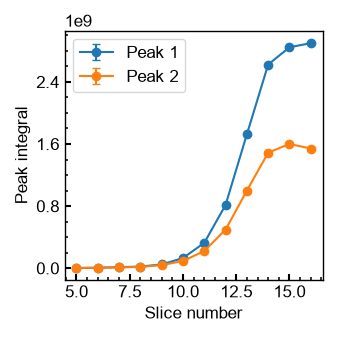

In [39]:
fig, ax = nmr.NMR2D_plot_integrals(
    fitted["rows"], tick_dir="in", tick_width=1.5, tick_number=5, show_right_spine=True, show_top_spine=True,
)

`NMR2D_summary_plot` exposes the contour panel's projections and colour scheme directly, instead of needing `contour_kwargs`:

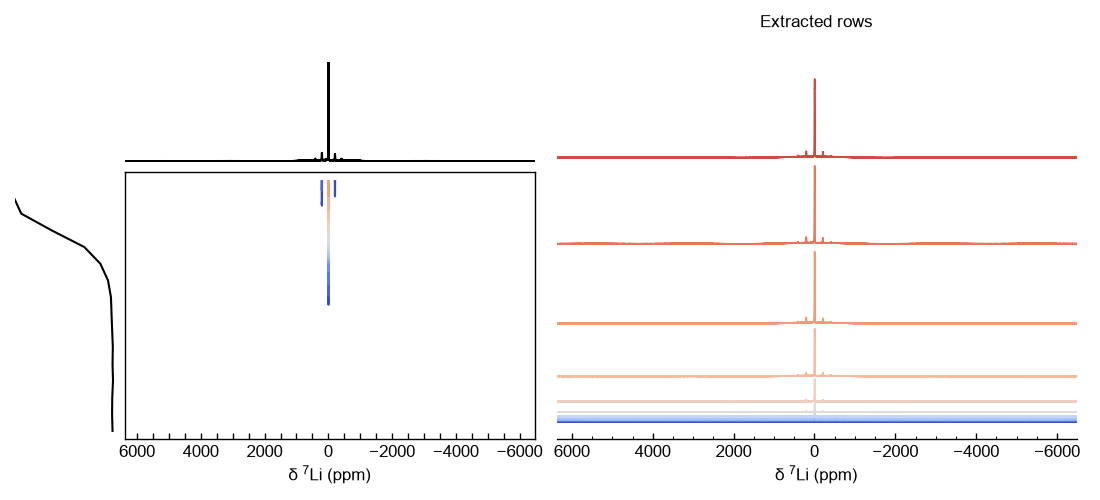

In [40]:
fig, axes = nmr.NMR2D_summary_plot(
    ds, slices=slices, slices_mode="rows",
    show_projections=True, projection_mode="sum", colour_spectra="coolwarm",
    factor=5e-2, clevels=20, projection_size=1.0, 
)

[1.0000000e-05 2.8000000e-05 8.0000000e-05 2.2700000e-04 6.4200000e-04
 1.8170000e-03 5.1440000e-03 1.4559000e-02 4.1211000e-02 1.1665200e-01
 3.3019300e-01 9.3464000e-01 2.6455810e+00 7.4885500e+00 2.1197005e+01
 6.0000000e+01]


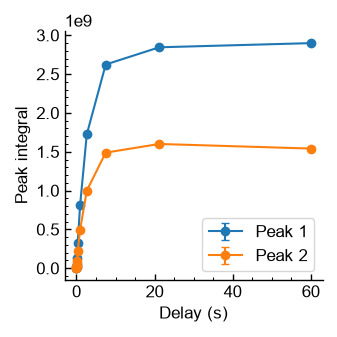

In [41]:
vd = nmr.read_vdlist(r"C:\Users\quark\Documents\NMR\500_MHz_Lyon\1p3mm_7Li_Li_TNb2O5_1p3V_20251124\2", vdlist_name='vdlist')
print(vd["seconds"])   # delays, in seconds, one per slice

fig, ax = nmr.NMR2D_plot_integrals(fitted["rows"], x_axis="vdlist")
# or explicitly: x_axis="vdlist", vdlist=vd  (or a path, or an array of seconds)